# FINN: эксперимент с моделью скачкообразной диффузии Мертона ($\lambda \in \{0, 1, 3, 5\}$)

Европейский call-опцион, $r = 0$. Траектории Мертона со скачками ($\lambda \in \{0, 1, 3, 5\}$) под риск-нейтральной мерой $\mathbb{Q} \to$ FINN $\to$ аналитическая цена и $\Delta$ Мертона.
Архитектура сети: **2 → 50 → 50 → 1**, функции активации `tanh` и `softplus`.

- При $\lambda = 0$ (санити-чек) генератор траекторий и формула Мертона в точности сводятся к GBM и Black–Scholes.
- При $\lambda > 0$ в `Config.__post_init__` параметры отдельного скачка $\mu_J, \sigma_J$ автоматически масштабируются в $1/\sqrt{\lambda}$ раз так, что годовой вклад скачков $\lambda(\mu_J^2 + \sigma_J^2) = 0.008$ остаётся константой, а суммарная дисперсия процесса $\sigma_{\text{diff}}^2 + \lambda(\mu_J^2 + \sigma_J^2)$ всегда равна $\sigma^2$.
- Серия: **4 интенсивности скачков ($\lambda \in \{0, 1, 3, 5\}$)** $\times$ **3 уровня волатильности ($\sigma \in \{0.125, 0.150, 0.175\}$)** $\times$ **10 независимых seed (42–51)** — по 30 моделей на каждую $\lambda$ (всего 120 моделей).


In [1]:
from __future__ import annotations

import base64
import csv
import hashlib
import io
import json
import math
import os
import platform
import shutil
import sys
import time
from dataclasses import asdict, replace
from datetime import datetime
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import HTML, Image, display
from scipy.optimize import brentq
from scipy.special import ndtr
from scipy.stats import poisson

# Подключение модуля обучения finn_merton_train из папки PY/ или корня проекта
cwd = Path.cwd().resolve()
project_dir = cwd.parent if cwd.name == "ipynb" else cwd

for folder in (project_dir / "PY", project_dir):
    if folder.is_dir() and str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import finn_merton_train as trainer
from finn_merton_train import (
    LAMBDA_LEVELS, Config, FINN, DATA_COLUMNS, SAMPLE_COLUMNS,
    simulate_merton_components, simulate_merton, merton_step_to_maturity,
    make_dataset, fixed_dataset, device_dataset, sample_batch,
    losses, validation, read_json, read_history, load_checkpoint,
    restore_model, write_json, train, run_directory, execution_settings,
    checked_training_summary, train_job, read_training_plan, train_study, launch_training,
)

print(f"Модуль обучения импортирован: {trainer.__file__}")


Модуль обучения импортирован: /content/VKR/PY/finn_merton_train.py


## 2. Конфигурация и параметры серий (калибровка дисперсии скачков)

Определение параметров базовой модели `Config`:
- $S_0 = 100$, $r = 0$, $dt = 1/250$, горизонт 2 года, сроки $\tau \sim U(0, 2)$, $m = S/K \sim U(0.5, 2.0)$, страйки $K = S / m$;
- Базовые параметры скачка при $\lambda = 1$: $\mu_J = -0.04$, $\sigma_J = 0.08$, базовая дисперсия скачков $V_J = (-0.04)^2 + 0.08^2 = 0.008$;
- При любом $\lambda > 0$ автоматически выполняется масштабирование:
  $$\mu_J(\lambda) = \frac{-0.04}{\sqrt{\lambda}}, \qquad \sigma_J(\lambda) = \frac{0.08}{\sqrt{\lambda}} \implies \lambda\left(\mu_J(\lambda)^2 + \sigma_J(\lambda)^2
ight) \equiv 0.008 = \text{const},$$
  а диффузионная волатильность вычисляется как $\sigma_{\text{diff}} = \sqrt{\sigma^2 - 0.008}$, поэтому общая дисперсия процесса всегда равна $\sigma^2$;
- Серия: 4 интенсивности $\lambda \in \{0, 1, 3, 5\} \times 3$ уровня $\sigma \in \{0.125, 0.150, 0.175\} \times 10$ seed (по 30 запусков на каждую $\lambda$).


In [2]:
# Фиксированные выборки и параметры серий Мертона
base_cfg = Config(
    seed=42,
    data_seed=42,
    sigma=0.15,
    jump_intensity=1.0,  # Базовое значение; серии запускаются для всех lambda_levels = [0.0, 1.0, 3.0, 5.0].
    jump_log_mean=-0.04,  # Калибровка: при lambda=1 вклад скачков mu_J^2+sigma_J^2=0.008 < 0.125^2.
    jump_log_std=0.08,
    sampling="spot_over_strike",  # m=S/K, K=S/m.
    m_min=0.5,
    m_max=2.0,
    min_tau=0.0,  # tau ~ U(0,2); при tau<dt переход заканчивается в экспирацию.
    max_tau=2.0,
    path_horizon=2.0,
    train_paths=400,
    validation_paths=100,
    transitions_per_path=100,  # Ровно 40 000 / 10 000 примеров.
    test_samples=10000,
    atm_fraction=0.0,
    transition_protocol="merton_uniform_tau_short_step_v1",  # Без принудительной квоты экспираций.
    epochs=250,
    steps_per_epoch=100,
    batch_size=512,
    lr_final_ratio=1.0,  # Постоянный lr=5e-4, как в принятом опыте.
    device="cuda" if torch.cuda.is_available() else "cpu",
)

cfg = base_cfg
checkpoint = None  # None: 4 lambda × 3 sigma × 10 seed; путь: оценка одного checkpoint.
lambda_levels = list(LAMBDA_LEVELS)  # [0.0, 1.0, 3.0, 5.0]
run_seeds = [42, 43, 44, 45, 46, 47, 48, 49, 50, 51]  # Заранее фиксированный список, без отбора по результату.
reuse_studies = {
    0.0: "merton_call_96b93176ceae383c",
    1.0: "merton_call_55a81edfc3bf8b27",
    3.0: "merton_call_1a849c20ed165fac",
    5.0: "merton_call_63fb5abc46e596c9",
}
volatility_levels = [0.125, 0.15, 0.175]
training_workers = 10  # Число одновременных обучений на GPU ядра; 1 — последовательный контроль.
worker_threads = 1  # CPU-потоки PyTorch на рабочий процесс; параметры Config не меняются.

notebook_path = (project_dir / "ipynb" / "finn_merton.ipynb") if (project_dir / "ipynb" / "finn_merton.ipynb").is_file() else (project_dir / "finn_merton.ipynb")
results_root = project_dir / "outputs"
print("Папка результатов:", results_root)
print("Интенсивности скачков λ:", lambda_levels)


Папка результатов: /content/VKR/outputs
Интенсивности скачков λ: [0.0, 1.0, 3.0, 5.0]


## 3. Моделирование процесса Мертона и подготовка обучающих данных

Генерация рыночных траекторий со скачками под риск-нейтральной мерой $\mathbb{Q}$:
- $S_0 = 100$, $r = 0$, $dt = 1/250$, горизонт 2 года (500 дневных интервалов), дрейф под $\mathbb{Q}$ равен $-\lambda \kappa - \frac{1}{2}\sigma_{\text{diff}}^2$;
- 400 независимых train- и 100 validation-траекторий; по 100 разных начальных шагов с каждой (итого 40 000 train и 10 000 validation);
- Moneyness $m = S/K \sim U(0.5, 2.0)$, срок $\tau \sim U(0, 2)$, шаг перехода $h = \min(dt, \tau)$;
- При $h < dt$ промежуточный шаг $S_{t+h}$ достраивается условным винеровским и биномиально-пуассоновским мостом (при $\lambda = 0$ тождественно совпадает с GBM).


In [3]:
# Функции моделирования скачкообразной диффузии Мертона и генерации выборок

def simulate_merton_paths(cfg: Config, num_paths: int, seed: int) -> np.ndarray:
    """Генерация траекторий Мертона под мерой Q (при jump_intensity=0 совпадает с simulate_gbm)."""
    return trainer.simulate_merton(cfg, num_paths, seed)

def make_merton_dataset(cfg: Config, split: str) -> dict[str, np.ndarray]:
    """Генерация фиксированных переходов (S, S_next, K, tau, tau_next, h, jump_count)."""
    return trainer.make_dataset(cfg, split)

print(f"Инициализация генерации данных: train={cfg.train_samples}, val={cfg.validation_samples}")


Инициализация генерации данных: train=40000, val=10000


## 4. Архитектура нейросети FINN (Finance-Informed Neural Network)

Структура сети $2 \to 50 \to 50 \to 1$:
- Вход сети: нормализованная цена спот $S/K$ и оставшийся срок до погашения $\tau$;
- Скрытые слои: 2 полносвязных слоя по 50 нейронов с функцией активации $\tanh$;
- Выходной слой: 1 нейрон с функцией активации `softplus` (выход $C/K$, денежная цена восстанавливается умножением на $K$);
- Аналитическая $\Delta$: производная цены по споту $\frac{\partial C}{\partial S}$ через `torch.autograd.grad`.


In [4]:
# Определение архитектуры нейросети FINN
model_preview = FINN()
print(f"Параметров модели FINN: {sum(p.numel() for p in model_preview.parameters())}")
del model_preview


Параметров модели FINN: 2751


## 5. Денежная ошибка хеджирования (Hedging Loss)

Функция потерь основана на денежном остатке дельта-хеджирования при $r = 0$:
$$R = \Delta \cdot (S_{\text{next}} - S) - (C_{\text{next}} - C), \qquad \mathcal{L} = \frac{1}{B} \sum_{i=1}^B R_i^2$$
- Точная выплата при экспирации: при $\tau_{\text{next}} = 0 \implies C_{\text{next}} = \max(S_{\text{next}} - K, 0)$;
- Сетевая цена при $\tau_{\text{next}} > 0$: вычисляется через саму сеть FINN;
- Никаких терминальных или intrinsic-штрафов во время обучения нет; ограничение снизу $\max(C_{\text{raw}}, (S-K)^+)$ применяется только при оценке.


In [5]:
# Функции расчёта ошибки хеджирования и валидации подключены из finn_merton_train
print("Функции расчёта ошибки хеджирования подключены:", losses.__name__, validation.__name__)


Функции расчёта ошибки хеджирования подключены: losses validation


## 6.1 Регистрация плана серии и рабочей директории

Формирование плана серии `study.json` (по 30 запусков: 3 волатильности $\sigma \times 10$ seed для каждого уровня $\lambda \in \{0, 1, 3, 5\}$):
- Каталог серии именуется уникальным хешем параметров (`merton_call_<hash>`);
- Сохраняются конфигурация `study.json`, снимок окружения и исходный код обучающего скрипта `training_source.json`.


In [6]:
# Функции подготовки рабочей директории и плана серии

TABLE_MATURITIES = (0.24, 0.28, 0.32, 0.36, 0.40, 0.44, 0.48)
METRICS = ("RMAD", "RMSE_relative", "NMAD", "MSE")

def write_csv(path: Path, rows: list[dict]) -> None:
    if not rows:
        return
    temporary = path.with_suffix(path.suffix + ".tmp")
    with temporary.open("w", newline="", encoding="utf-8-sig") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    temporary.replace(path)

def prepare_study(root: Path, configurations: list[Config],
                  workers: int = 10, worker_threads: int = 1,
                  existing_study: str | None = None) -> Path:
    if existing_study:
        existing_dir = Path(root) / existing_study
        if (existing_dir / "study.json").is_file() and all(
                completed_report(existing_dir, c) is not None for c in configurations):
            return existing_dir
    plan = {
        "protocol_version": "merton_call_uniform_tau_short_step_v1",
        "option": "European call", "architecture": [2, 50, 50, 1],
        "configurations": [asdict(c) for c in configurations],
        "execution": execution_settings(workers, worker_threads),
        "maturities": list(TABLE_MATURITIES),
        "data_protocol": "Fixed train/validation; distinct daily intervals per path; m=S/K uniform [0.5,2]; tau uniform [0,2]; h=min(dt,tau); conditional Wiener and marked-Poisson bridge for h<dt; no expiry quota",
        "loss_protocol": "Mean squared monetary hedging residual; exact payoff at tau_next=0, network price at positive tau; no terminal/intrinsic penalties",
        "prediction_protocol": "Price=max(raw network price, intrinsic); Delta=derivative of this bounded price; floor applied only at evaluation",
        "implementation_note": "Clipping the step at expiry and the prediction-only floor are implementation choices, not a confirmed reproduction of the paper boundary handling",
        "plot_error_sign": "Merton - FINN (Appendix F.1)",
        "test_protocol": "10,000 independent-test pairs: GBM S filtered to [75,125], K uniform [75,125]; reused at all seven maturities",
        "aggregation": "Per-run metrics; mean and sample std (ddof=1) only across runs; std unavailable for a single seed",
        "source": "arXiv:2412.12213v2, Table 9 and Appendix F.1; K range and test count adopted from v1 Table 1; S sampling and uniform K are explicit implementation choices",
        "environment": {"python": platform.python_version(), "torch": str(torch.__version__), "numpy": np.__version__},
    }
    signature = hashlib.sha256(json.dumps(plan, sort_keys=True).encode()).hexdigest()[:16]
    directory = root / f"merton_call_{signature}"
    directory.mkdir(parents=True, exist_ok=True)
    plan_path = directory / "study.json"
    if plan_path.exists():
        if json.loads(plan_path.read_text(encoding="utf-8")) != plan:
            raise ValueError("Saved study settings differ from the current configuration")
    else:
        write_json(plan_path, plan)
    if notebook_path.is_file() and not (directory / "finn_merton_source.ipynb").exists():
        (directory / "finn_merton_source.ipynb").write_bytes(notebook_path.read_bytes())
    script_source = Path(trainer.__file__).read_bytes()
    if hashlib.sha256(script_source).hexdigest() != plan["execution"]["training_script_sha256"]:
        raise RuntimeError("Скрипт изменился при подготовке серии")
    write_json(directory / "training_source.json", {
        "filename": "finn_merton_train.py", "sha256": plan["execution"]["training_script_sha256"],
        "source": script_source.decode("utf-8"),
    })
    return directory


## 6.2 Контроль завершённых запусков и повторное использование

Функции проверки готовности отдельных моделей и переноса чекпоинтов:
- `completed_report`: проверяет наличие и целостность `complete.json`, `metrics.json`, `best_model.pt`, `training_summary.json` и всех 14 строк метрик по срокам;
- `reuse_completed_runs`: копирует полностью завершённые совместимые запуски из существующей папки серии.


In [7]:
# Функции контроля завершённых запусков серии

def completed_report(directory: Path, cfg: Config) -> dict | None:
    folder = run_directory(directory, cfg)
    required = ("complete.json", "metrics.json", "best_model.pt", "training_summary.json")
    if not all((folder / name).is_file() for name in required):
        return None
    marker = json.loads((folder / "complete.json").read_text(encoding="utf-8"))
    if marker["config"] != asdict(cfg):
        raise ValueError(f"Configuration mismatch: {folder}")
    report = json.loads((folder / "metrics.json").read_text(encoding="utf-8"))
    rows = report["by_maturity"]
    expected = {(t, q) for t in TABLE_MATURITIES for q in ("price", "delta")}
    if len(rows) != len(expected) or {(r["tau"], r["quantity"]) for r in rows} != expected:
        raise ValueError(f"Incomplete maturity metrics: {folder}")
    if report["evaluation"]["seed"] != cfg.seed or report["evaluation"]["sigma"] != cfg.sigma:
        raise ValueError(f"Evaluation metadata mismatch: {folder}")
    for row in rows:
        if row["count"] != cfg.test_samples:
            raise ValueError(f"Incorrect number of test contracts: {folder}")
        for key in ("RMAD", "RMSE_relative", "NMAD", "MSE"):
            if row[key] is None or not math.isfinite(row[key]):
                raise ValueError(f"Missing or non-finite {key}: {folder}")
    return report

def reuse_completed_runs(directory: Path, configurations: list[Config], source_directory: Path) -> int:
    """Копируем только полностью завершённые совместимые запуски; источник не меняем."""
    directory, source_directory = directory.resolve(), source_directory.resolve()
    source_plan_path = source_directory / "study.json"
    if source_directory == directory or not source_plan_path.is_file():
        return 0
    source_plan = json.loads(source_plan_path.read_text(encoding="utf-8"))
    target_plan = json.loads((directory / "study.json").read_text(encoding="utf-8"))
    ignore_keys = {"configurations", "execution"}
    if ({k: v for k, v in source_plan.items() if k not in ignore_keys}
            != {k: v for k, v in target_plan.items() if k not in ignore_keys}):
        print("Прежняя серия отличается по протоколу или среде: запускаем новые обучения.", flush=True)
        return 0
    copied = 0
    for cfg in configurations:
        if asdict(cfg) not in source_plan.get("configurations", []):
            continue
        target = run_directory(directory, cfg).resolve()
        source = run_directory(source_directory, cfg)
        if target.exists() or completed_report(source_directory, cfg) is None:
            continue
        if not all((source / name).is_file() for name in
                   ("config.json", "history.csv", "train_samples.npz", "validation_samples.npz")):
            continue
        temporary = target.with_name(f".{target.name}_import_{time.time_ns()}")
        if not (target.is_relative_to(directory) and temporary.resolve().is_relative_to(directory)):
            raise ValueError("Run destination escapes the current study")
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copytree(source, temporary)
        temporary.replace(target)
        write_json(target / "reused_from.json", {"source_study": source_directory.name,
                                                  "sigma": cfg.sigma, "seed": cfg.seed})
        copied += 1
    return copied


## 6.3 Инициализация списков конфигураций серий для $\lambda \in \{0, 1, 3, 5\}$

Формирование сетки из 4 серий по 30 экспериментов (3 значения $\sigma \times 10$ сидов на каждую $\lambda$) и подготовка рабочих каталогов `out_by_lambda`:
- Проверяется наличие готовых серий в `reuse_studies`;
- Выводятся пути к каталогам всех четырёх серий.


In [8]:
# Инициализация конфигураций для 4 серий λ ∈ {0, 1, 3, 5} (по 30 запусков в каждой)

saved = None
if checkpoint is not None:
    checkpoint = Path(checkpoint)
    if not checkpoint.is_absolute():
        checkpoint = project_dir / checkpoint
    saved = load_checkpoint(checkpoint, cfg.device)
    device, threads = cfg.device, cfg.threads
    evaluation_settings = {name: getattr(cfg, name) for name in
                           ("test_samples", "test_paths", "test_spot_min", "test_spot_max",
                            "test_strike_min", "test_strike_max", "price_mask", "delta_mask",
                            "surface_sigma", "surface_tau", "path_horizon", "dt")}
    restored = dict(saved["config"])
    restored.pop("diagnostic_every", None)
    restored.pop("validation_samples", None)
    for old_key in ("intrinsic_weight", "terminal_multiplier", "terminal_weight",
                    "objective_scale", "hedge_normalization", "exact_expiry", "expiry_fraction"):
        restored.pop(old_key, None)
    restored.setdefault("sampling", "spot_over_strike")
    if restored.get("min_tau") is None:
        restored["min_tau"] = restored["dt"]
    restored.setdefault("lr_final_ratio", 1.0)
    restored.setdefault("transition_protocol", "legacy_fixed_dt")
    restored.update(evaluation_settings)
    cfg = Config(**restored)
    cfg.device, cfg.threads = device, threads
torch.set_num_threads(cfg.threads)

if saved is None:
    study_configs_by_lambda = {}
    out_by_lambda = {}
    for lmbd in lambda_levels:
        cfgs_lmbd = [
            replace(base_cfg, jump_intensity=lmbd, sigma=sigma, seed=seed, data_seed=seed)
            for sigma in volatility_levels for seed in run_seeds
        ]
        existing_name = reuse_studies.get(lmbd)
        out_dir = prepare_study(results_root, cfgs_lmbd, training_workers, worker_threads, existing_study=existing_name)
        if existing_name and out_dir.name != existing_name and (results_root / existing_name).is_dir():
            reused = reuse_completed_runs(out_dir, cfgs_lmbd, results_root / existing_name)
            if reused:
                print(f"λ={lmbd:g}: перенесено завершённых запусков: {reused}", flush=True)
        study_configs_by_lambda[lmbd] = cfgs_lmbd
        out_by_lambda[lmbd] = out_dir
        print(f"λ={lmbd:g}: серия {len(cfgs_lmbd)} запусков -> {out_dir}")
    study_configs = study_configs_by_lambda[lambda_levels[0]]
    out = out_by_lambda[lambda_levels[0]]
else:
    out = results_root / f"merton_evaluation_{datetime.now():%Y%m%d_%H%M%S_%f}_seed{cfg.seed}"
    out.mkdir(parents=True, exist_ok=False)
    write_json(out / "config.json", asdict(cfg))
    write_json(out / "environment.json", {"python": platform.python_version(), "torch": str(torch.__version__),
                                         "numpy": np.__version__, "device": cfg.device})
    print("Результаты:", out)


λ=0: серия 30 запусков -> /content/VKR/outputs/merton_call_2053cc57e1be9b60
λ=1: серия 30 запусков -> /content/VKR/outputs/merton_call_534898fa7430d394
λ=3: серия 30 запусков -> /content/VKR/outputs/merton_call_3edc1bacf0aa4220
λ=5: серия 30 запусков -> /content/VKR/outputs/merton_call_8082d1f342b86542


## 7.1 Фиксированная тестовая выборка и аналитическая формула Мертона

Подготовка независимой тестовой выборки и аналитического эталона Мертона:
- В каждом запуске ровно 10 000 пар $(S, K)$: $S$ из независимых траекторий Мертона (`SeedSequence([cfg.effective_data_seed, 2])`) с отбором в $[75, 125]$, страйки $K \sim U(75, 125)$;
- Одни и те же 10 000 пар $(S, K)$ данного `seed` используются на всех семи сроках $\tau \in \{0.24, 0.28, 0.32, 0.36, 0.40, 0.44, 0.48\}$;
- Эталон — аналитическая пуассоновская смесь Black–Scholes для цены и $\Delta$ Мертона с калиброванной $\sigma_{\text{diff}}$ (при $\lambda = 0$ в точности равна Black–Scholes).


In [9]:
# Независимая тестовая выборка каждого запуска и аналитическая формула Мертона

def black_scholes(s: np.ndarray, k: np.ndarray, tau: np.ndarray,
                  sigma: float) -> tuple[np.ndarray, np.ndarray]:
    """Европейский call Black–Scholes, r=0, tau>0."""
    d1 = (np.log(s / k) + 0.5 * sigma**2 * tau) / (sigma * np.sqrt(tau))
    d2 = d1 - sigma * np.sqrt(tau)
    return s * ndtr(d1) - k * ndtr(d2), ndtr(d1)

def merton_price_delta(s: np.ndarray, k: np.ndarray, tau: np.ndarray,
                       cfg: Config, *, tail_tolerance: float = 1e-12) -> tuple[np.ndarray, np.ndarray]:
    """Аналитическая цена и Delta Мертона с калиброванной diffusion_sigma; при jump_intensity=0 равна black_scholes."""
    sigma_diff = cfg.diffusion_sigma
    if cfg.jump_intensity == 0:
        return black_scholes(s, k, tau, sigma_diff)
    s, k, tau = np.broadcast_arrays(np.asarray(s, dtype=np.float64),
                                    np.asarray(k, dtype=np.float64),
                                    np.asarray(tau, dtype=np.float64))
    mean_count = cfg.jump_intensity * tau
    stock_count = cfg.jump_intensity * (1.0 + cfg.jump_kappa) * tau
    max_mean = float(max(np.max(mean_count), np.max(stock_count)))
    n_max = 0 if max_mean == 0 else int(poisson.isf(tail_tolerance, max_mean))
    while poisson.sf(n_max, max_mean) > tail_tolerance:
        n_max += 1
    call, delta = np.zeros_like(s), np.zeros_like(s)
    drift = (-cfg.jump_intensity * cfg.jump_kappa - 0.5 * sigma_diff**2) * tau
    for n in range(n_max + 1):
        std = np.sqrt(sigma_diff**2 * tau + n * cfg.jump_log_std**2)
        d2 = (np.log(s / k) + drift + n * cfg.jump_log_mean) / std
        d1 = d2 + std
        weight = poisson.pmf(n, mean_count)
        stock_weight = poisson.pmf(n, stock_count)
        stock_leg = stock_weight * ndtr(d1)
        call += s * stock_leg - k * weight * ndtr(d2)
        delta += stock_leg
    return call, delta

def predict(model: FINN, s: np.ndarray, k: np.ndarray, tau: np.ndarray,
            cfg: Config) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    prices, deltas = [], []
    with torch.enable_grad():
        for start in range(0, len(s), cfg.batch_size):
            values = (s[start:start + cfg.batch_size], k[start:start + cfg.batch_size],
                      tau[start:start + cfg.batch_size])
            st, kt, tt = [torch.as_tensor(v.reshape(-1, 1), dtype=torch.float32,
                                         device=cfg.device) for v in values]
            st = st.detach().requires_grad_(True)
            p = model.bounded_price(st, kt, tt)  # Цена и Delta после одной корректировки.
            delta = torch.autograd.grad(p.sum(), st)[0]
            prices.append(p.detach().cpu().numpy().ravel())
            deltas.append(delta.detach().cpu().numpy().ravel())
    return np.concatenate(prices), np.concatenate(deltas)

def test_contracts(cfg: Config) -> tuple[np.ndarray, np.ndarray, int]:
    """10 000 разных состояний из независимых траекторий Мертона; S и K в [75,125]."""
    path_seed, sample_seed = np.random.SeedSequence([cfg.effective_data_seed, 2]).spawn(2)
    path_rng = np.random.default_rng(path_seed)
    rng = np.random.default_rng(sample_seed)
    pools, count, path_count = [], 0, 0
    while count < cfg.test_samples:
        paths = simulate_merton(cfg, cfg.test_paths, path_rng)
        states = paths[:, 1:].ravel()
        eligible = states[(states >= cfg.test_spot_min) & (states <= cfg.test_spot_max)]
        pools.append(eligible)
        count += eligible.size
        path_count += cfg.test_paths
    states = np.concatenate(pools)
    s = states[rng.choice(states.size, cfg.test_samples, replace=False)]
    k = rng.uniform(cfg.test_strike_min, cfg.test_strike_max, cfg.test_samples)
    return s, k, path_count

print("Тестовая выборка (потоки SeedSequence [data_seed, 2]), аналитическая модель Мертона и predict подготовлены")


Тестовая выборка (потоки SeedSequence [data_seed, 2]), аналитическая модель Мертона и predict подготовлены


## 7.2 Оценка чекпоинта FINN на 7 сроках Table 9 (Appendix F.1)

Процедура вычисления метрик качества на отложенных сроках $\tau \in \{0.24, 0.28, \dots, 0.48\}$ в точном соответствии с `arXiv:2412.12213v2, Appendix F.1` (формулы 62, 63, 67, 68):
- Ограничение снизу intrinsic floor при оценке: $C = \max(C_{\text{raw}}, (S-K)^+)$, $\Delta = \frac{\partial C}{\partial S}$;
- Ошибка $e = y - \hat{y} = \text{Merton} - \text{FINN}$;
- На маске $|y| \ge \text{tolerance}$ вычисляются:
  $$\text{RMAD} = \frac{\sum |e_m|}{\sum |y_m|}, \qquad \text{RMSE}_{\text{rel}} = \sqrt{\frac{\sum e_m^2}{\sum y_m^2}}, \qquad \text{NMAD} = \frac{\text{mean}(|e_m|)}{\max(y_m) - \min(y_m)}$$
- На всех точках вычисляется $\text{MSE} = \text{mean}(e^2)$.


In [10]:
# Функции расчёта метрик Appendix F.1 (paper_metrics) и оценки чекпоинта (evaluate)

def paper_metrics(pred: np.ndarray, target: np.ndarray, tolerance: float) -> dict:
    """Метрики F.1: RMAD (62), relative RMSE (63), NMAD (67), MSE (68).

    Первые три — на маске |target| >= tolerance; MSE — на всех точках
    согласно явной формуле (68). count и mask_tolerance описывают выборку.
    """
    pred, target = np.asarray(pred, dtype=float), np.asarray(target, dtype=float)
    if pred.shape != target.shape or pred.size == 0:
        raise ValueError("Metrics require nonempty arrays of identical shape")
    if not np.isfinite(pred).all() or not np.isfinite(target).all():
        raise ValueError("Non-finite prediction or reference")
    mask = np.abs(target) >= tolerance
    e = target - pred  # F.1: Merton - FINN; абсолютные/квадратичные метрики не меняются.
    result = {"count": int(target.size), "masked_count": int(mask.sum()),
              "mask_tolerance": tolerance, "MSE": float(np.mean(e**2))}
    if not mask.any():
        result.update(RMAD=None, RMSE_relative=None, NMAD=None)
    else:
        y, em = target[mask], e[mask]
        result.update(RMAD=float(np.abs(em).sum() / (np.abs(y).sum() + 1e-12)),
                      RMSE_relative=float(np.sqrt(np.sum(em**2) / (np.sum(y**2) + 1e-12))),
                      NMAD=float(np.abs(em).mean() / (np.ptp(y) + 1e-12)))
    return result

def prediction_grid(cfg: Config) -> tuple:
    ss, kk = np.meshgrid(np.linspace(80, 120, 41), np.linspace(90, 110, 21), indexing="ij")
    m = np.linspace(0.5, 2.0, 301)
    spots = np.concatenate((ss.ravel(), 100 * m))
    strikes = np.concatenate((kk.ravel(), np.full_like(m, 100)))
    times = np.full_like(spots, cfg.surface_tau)
    return ss, kk, spots, strikes, times

def draw_prediction_plots(directory: Path, cfg: Config, ss: np.ndarray, kk: np.ndarray,
                          spots: np.ndarray, predictions: np.ndarray, truth: np.ndarray,
                          std: np.ndarray | None = None, count: int = 1) -> None:
    """Одинаковые сетки и оформление для одной модели и среднего по seed."""
    label = "FINN" if count == 1 else f"FINN mean ({count} seeds)"
    errors = truth - predictions
    fig = plt.figure(figsize=(13, 10))
    for i, quantity in enumerate(("Price", "Delta")):
        ax = fig.add_subplot(2, 2, i + 1, projection="3d")
        for values, color, legend in ((predictions, "red", label), (truth, "green", "Merton")):
            ax.plot_wireframe(ss, kk, values[i, :ss.size].reshape(ss.shape), color=color,
                              rstride=1, cstride=1, linewidth=0.5, label=legend)
        ax.set(xlabel="S", ylabel="K", zlabel="C" if i == 0 else "Δ", title=quantity)
        ax.view_init(elev=30, azim=-135)
        ax.legend(loc="upper right", fontsize=8)
        ax = fig.add_subplot(2, 2, i + 3, projection="3d")
        ax.plot_surface(ss, kk, errors[i, :ss.size].reshape(ss.shape), cmap="coolwarm")
        ax.set(xlabel="S", ylabel="K", zlabel="Merton - FINN", title=f"{quantity} error")
        ax.view_init(elev=30, azim=-135)
    fig.suptitle(f"{label}; sigma={cfg.sigma}, tau={cfg.surface_tau}")
    fig.tight_layout()
    fig.savefig(directory / "surfaces.png", dpi=160)
    plt.close(fig)

    m = spots[ss.size:] / 100
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for i, quantity in enumerate(("Call price, K=100", "Delta")):
        estimate, reference = predictions[i, ss.size:], truth[i, ss.size:]
        axes[i, 0].plot(m, estimate, color="red", label=label)
        if std is not None:
            spread = std[i, ss.size:]
            axes[i, 0].fill_between(m, estimate - spread, estimate + spread, color="red", alpha=0.12,
                                    label="±1 std across seeds")
        axes[i, 0].plot(m, reference, "--", color="green", label="Merton")
        axes[i, 0].set_title(quantity)
        axes[i, 1].plot(m, reference - estimate, label="Merton - FINN")
        axes[i, 1].set(title="Price error" if i == 0 else "Delta error", ylabel="Merton - FINN")
    for ax in axes.flat:
        ax.set_xlabel("S/K")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    fig.suptitle(f"sigma={cfg.sigma}, tau={cfg.surface_tau}")
    fig.tight_layout()
    fig.savefig(directory / "comparison.png", dpi=160)
    plt.close(fig)

def draw_loss_plot(directory: Path, epochs: np.ndarray, curves: dict, title: str) -> None:
    fig, ax = plt.subplots(figsize=(8, 4))
    for label, values in curves.items():
        ax.semilogy(epochs, np.maximum(values, 1e-16), label=label)
    ax.set(title=title, xlabel="Epoch", ylabel="Mean squared monetary residual")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(directory / "training.png", dpi=160)
    plt.close(fig)

def plot_training_history(out: Path, cfg: Config) -> None:
    h = read_history(out / "history.csv")
    draw_loss_plot(out, h["epoch"], {split: h[f"{split}_loss"] for split in ("train", "val")},
                   "Hedging loss")

def plot_model_predictions(model: FINN, cfg: Config, directory: Path) -> None:
    ss, kk, spots, strikes, times = prediction_grid(cfg)
    predictions = np.stack(predict(model, spots, strikes, times, cfg))
    truth = np.stack(merton_price_delta(spots, strikes, times, cfg))
    draw_prediction_plots(directory, cfg, ss, kk, spots, predictions, truth)

def evaluate(model: FINN, cfg: Config, out: Path) -> dict:
    s, k, test_path_count = test_contracts(cfg)
    np.savetxt(out / "test_contracts.csv", np.column_stack((s, k)), delimiter=",",
               header="S,K", comments="", fmt="%.17g")
    metrics = {"evaluation": {"sigma": cfg.sigma, "diffusion_sigma": cfg.diffusion_sigma, "seed": cfg.seed,
               "data_seed": cfg.effective_data_seed, "jump_intensity": cfg.jump_intensity,
               "jump_log_mean": cfg.jump_log_mean, "jump_log_std": cfg.jump_log_std,
               "test_points": cfg.test_samples,
               "test_paths": test_path_count, "strike_range": [cfg.test_strike_min, cfg.test_strike_max],
               "spot_range": [cfg.test_spot_min, cfg.test_spot_max],
               "realized_spot_range": [float(s.min()), float(s.max())],
               "sampling": "S from independent GBM after t=0, filtered to [75,125]; K uniform [75,125]; same pairs at every maturity",
               "metric_source": "arXiv:2412.12213v2, Appendix F.1",
               "prediction_protocol": "Intrinsic floor at evaluation; delta of bounded price",
               "protocol_note": "GBM spot sampling and uniform K are explicit choices; the authors do not fully specify the joint test distribution."}}
    rows = []
    maturities = [t for t in TABLE_MATURITIES if t <= cfg.max_tau + 1e-9]
    for t in maturities:
        sv, kv = s, k
        times = np.full_like(sv, t)
        p, d = predict(model, sv, kv, times, cfg)
        ref, rd = merton_price_delta(sv, kv, times, cfg)
        for label, estimate, truth, tol in (("price", p, ref, cfg.price_mask),
                                            ("delta", d, rd, cfg.delta_mask)):
            rows.append({"sigma": cfg.sigma, "tau": t, "quantity": label,
                         **paper_metrics(estimate, truth, tol)})
    write_csv(out / "metrics_by_maturity.csv", rows)
    metrics["by_maturity"] = rows
    write_json(out / "metrics.json", metrics)
    if math.isclose(cfg.sigma, cfg.surface_sigma, rel_tol=0, abs_tol=1e-12):
        plot_model_predictions(model, cfg, out)
        plot_training_history(out, cfg)
    return metrics

print("Функции paper_metrics и evaluate (Appendix F.1) для модели Мертона определены")


Функции paper_metrics и evaluate (Appendix F.1) для модели Мертона определены


## 7.3 Запуск параллельного обучения серий на GPU

Запуск фонового скрипта `finn_merton_train.py` через `launch_training` для всех $\lambda \in \{0, 1, 3, 5\}$:
- До `training_workers` параллельных изолированных процессов на GPU;
- Полностью сохранённые и проверенные серии пропускаются автоматически;
- По завершении каждого seed загружается лучший чекпоинт `best_model.pt` и формируется `metrics.json`.


In [11]:
# Запуск параллельного обучения серий моделей и оценка чекпоинтов

def run_study(configurations: list[Config], directory: Path,
              workers: int = 10, worker_threads: int = 1) -> None:
    """Дождаться обучения в скрипте, затем оценить модели в основном ядре."""
    directory = Path(directory)
    plan = read_json(directory / "study.json")
    if plan["configurations"] != [asdict(cfg) for cfg in configurations]:
        raise ValueError("Конфигурации оценки отличаются от плана обучения")
    if all(completed_report(directory, cfg) is not None for cfg in configurations):
        print(f"λ={configurations[0].jump_intensity:g}: все {len(configurations)} запусков уже обучены и оценены в {directory.name}", flush=True)
        return
    status = launch_training(directory, workers, worker_threads)
    print(f"Обучение серии: {status['elapsed_seconds']:.1f} с; оценка выбранных checkpoint", flush=True)
    for index, cfg in enumerate(configurations, 1):
        folder = run_directory(directory, cfg)
        if completed_report(directory, cfg) is not None:
            print(f"[{index}/{len(configurations)}] sigma={cfg.sigma}, seed={cfg.seed}: сохранено", flush=True)
            continue
        summary = checked_training_summary(folder, cfg)
        if summary is None:
            raise FileNotFoundError(f"Обучение не завершено: {folder}")
        model = restore_model(load_checkpoint(folder / "best_model.pt", cfg.device, cfg), cfg.device)
        report = evaluate(model, cfg, folder)
        report["evaluated_checkpoint"] = {"epoch": summary["best_epoch"], "selection": "minimum_validation_loss"}
        write_json(folder / "metrics.json", report)
        write_json(folder / "complete.json", {"config": asdict(cfg)})
        print(f"Оценено {index}/{len(configurations)}", flush=True)
        del model

if saved is None:
    for lmbd in lambda_levels:
        print(f"=== Обучение и проверка серии λ = {lmbd:g} ===", flush=True)
        run_study(study_configs_by_lambda[lmbd], out_by_lambda[lmbd], training_workers, worker_threads)
else:
    model = restore_model(saved, cfg.device)


=== Обучение и проверка серии λ = 0 ===
λ=0: все 30 запусков уже обучены и оценены в merton_call_2053cc57e1be9b60
=== Обучение и проверка серии λ = 1 ===
λ=1: все 30 запусков уже обучены и оценены в merton_call_534898fa7430d394
=== Обучение и проверка серии λ = 3 ===
λ=3: все 30 запусков уже обучены и оценены в merton_call_3edc1bacf0aa4220
=== Обучение и проверка серии λ = 5 ===
λ=5: все 30 запусков уже обучены и оценены в merton_call_8082d1f342b86542


## 8. Сводные показатели Table 1 и Table 9 (Расчёт и отображение)

Расчёт и интерактивное отображение сводных показателей по 30 запускам для каждой интенсивности скачков $\lambda \in \{0, 1, 3, 5\}$:
- Сбор неусреднённых индивидуальных метрик лучших чекпоинтов по каждому `seed`;
- Усреднение и расчёт выборочного стандартного отклонения ($ddof = 1$) по 10 независимым сидам;
- Сохранение `table1.csv` (`RMAD`, `RMSE`), `table9.csv` (`NMAD`, `MSE`), `metrics_summary.csv`, `metrics_runs.csv` и отображение полных таблиц `mean (std)`.


In [12]:
# Сбор метрик отдельных запусков и формирование таблиц Table 1 / Table 9 для каждого λ ∈ {0, 1, 3, 5}

def collect_run_metrics(directory: Path, configurations: list[Config],
                        require_complete: bool = False) -> tuple[list[dict], list[tuple]]:
    """Метрики выбранных best checkpoint, без подстановки другой серии."""
    records, completed = [], []
    for cfg in configurations:
        report = completed_report(directory, cfg)
        if report is None:
            if require_complete:
                raise FileNotFoundError(f"Обучение или оценка не завершены: {run_directory(directory, cfg)}")
            continue
        completed.append((cfg.sigma, cfg.seed))
        for row in report["by_maturity"]:
            records.append({"sigma": cfg.sigma, "tau": row["tau"], "seed": cfg.seed,
                            "data_seed": cfg.effective_data_seed,
                            "checkpoint_epoch": report["evaluated_checkpoint"]["epoch"],
                            "quantity": row["quantity"], "count": row["count"],
                            "masked_count": row["masked_count"], "mask_tolerance": row["mask_tolerance"],
                            **{key: row[key] for key in METRICS}})
    return records, completed

def export_study_tables(directory: Path, configurations: list[Config]) -> tuple[dict, list[dict], list[dict]]:
    records, completed = collect_run_metrics(directory, configurations, require_complete=True)
    write_csv(directory / "metrics_runs.csv", records)
    numeric, formatted, main_table, summaries, full_pretty = [], [], [], [], []
    for sigma in sorted({c.sigma for c in configurations}):
        expected_runs = sum(c.sigma == sigma for c in configurations)
        for tau in TABLE_MATURITIES:
            selection = [r for r in records if r["sigma"] == sigma and r["tau"] == tau]
            if not selection:
                continue
            n_runs = len({r["seed"] for r in selection})
            row = {"sigma": sigma, "tau": tau, "n_runs": n_runs, "expected_runs": expected_runs}
            pretty = {"sigma": sigma, "tau": tau}
            main_pretty = {"sigma": sigma, "tau": tau}
            combined_row = {"sigma": sigma, "tau": tau}
            for quantity, label in (("price", "Call"), ("delta", "Delta")):
                summary = {"sigma": sigma, "tau": tau, "quantity": quantity,
                           "n_runs": n_runs, "expected_runs": expected_runs}
                for metric in METRICS:
                    values = [r[metric] for r in selection if r["quantity"] == quantity]
                    if len(values) != n_runs:
                        raise ValueError("Missing quantity in completed run")
                    mean = float(np.mean(values))
                    std = float(np.std(values, ddof=1)) if n_runs > 1 else None
                    summary[f"{metric}_mean"] = mean
                    summary[f"{metric}_std"] = std
                    value = f"{mean:.3f} ({std:.3f})" if std is not None else f"{mean:.3f} (n/a)"
                    combined_row[f"{label}_{metric}"] = value
                    if metric in ("NMAD", "MSE"):
                        row[f"{label}_{metric}_mean"] = mean
                        row[f"{label}_{metric}_std"] = std
                        pretty[f"{label}_{metric}"] = value
                    else:
                        main_pretty[f"{label}_{metric}"] = value
                summaries.append(summary)
            main_pretty.update(n_runs=n_runs, expected_runs=expected_runs)
            main_table.append(main_pretty)
            pretty.update(n_runs=n_runs, expected_runs=expected_runs)
            numeric.append(row)
            formatted.append(pretty)
            full_pretty.append(combined_row)
    complete = len(completed) == len(configurations)
    suffix = "" if complete else "_partial"
    write_csv(directory / f"metrics_summary{suffix}.csv", summaries)
    write_csv(directory / f"table1{suffix}.csv", main_table)
    write_csv(directory / f"table9_summary{suffix}.csv", numeric)
    write_csv(directory / f"table9{suffix}.csv", formatted)
    status = {"completed_runs": len(completed), "expected_runs": len(configurations),
              "complete": complete, "table": f"table9{suffix}.csv",
              "numeric_table": f"table9_summary{suffix}.csv",
              "all_metrics_summary": f"metrics_summary{suffix}.csv",
              "main_table": f"table1{suffix}.csv"}
    write_json(directory / "study_status.json", status)
    return status, records, full_pretty

if saved is None:
    status_by_lambda, raw_runs_by_lambda, table9_by_lambda = {}, {}, {}
    for lmbd in lambda_levels:
        out_dir = Path(out_by_lambda[lmbd])
        st, recs, t9 = export_study_tables(out_dir, study_configs_by_lambda[lmbd])
        status_by_lambda[lmbd] = st
        raw_runs_by_lambda[lmbd] = recs
        table9_by_lambda[lmbd] = t9
        print(f"λ={lmbd:g}: завершено {st['completed_runs']}/{st['expected_runs']} запусков -> {out_dir.name}")
    for lmbd in lambda_levels:
        body_t9 = []
        for r in table9_by_lambda[lmbd]:
            body_t9.append(
                f"<tr><td style='text-align:center'>{r['sigma']:.3f}</td><td style='text-align:center'>{r['tau']:.2f}</td>"
                f"<td>{r.get('Call_RMAD','')}</td><td>{r.get('Call_RMSE_relative','')}</td>"
                f"<td>{r.get('Call_NMAD','')}</td><td>{r.get('Call_MSE','')}</td>"
                f"<td>{r.get('Delta_RMAD','')}</td><td>{r.get('Delta_RMSE_relative','')}</td>"
                f"<td>{r.get('Delta_NMAD','')}</td><td>{r.get('Delta_MSE','')}</td></tr>"
            )
        display(HTML(
            f"<h4>λ = {lmbd:g}: сводные метрики FINN по 10 seed (Table 1: RMAD/RMSE и Table 9: NMAD/MSE, mean (std))</h4>"
            "<table><thead><tr><th>σ</th><th>τ</th>"
            "<th>Call RMAD</th><th>Call RMSE</th><th>Call NMAD</th><th>Call MSE</th>"
            "<th>Delta RMAD</th><th>Delta RMSE</th><th>Delta NMAD</th><th>Delta MSE</th></tr></thead>"
            "<tbody>" + "".join(body_t9) + "</tbody></table>"
        ))
else:
    metrics = evaluate(model, cfg, out)
    metrics["evaluated_checkpoint"] = {"epoch": saved.get("epoch"), "selection": "loaded_checkpoint"}
    write_json(out / "metrics.json", metrics)
    print("Метрики:", out / "metrics_by_maturity.csv")


λ=0: завершено 30/30 запусков -> merton_call_2053cc57e1be9b60
λ=1: завершено 30/30 запусков -> merton_call_534898fa7430d394
λ=3: завершено 30/30 запусков -> merton_call_3edc1bacf0aa4220
λ=5: завершено 30/30 запусков -> merton_call_8082d1f342b86542


σ,τ,Call RMAD,Call RMSE,Call NMAD,Call MSE,Delta RMAD,Delta RMSE,Delta NMAD,Delta MSE
0.125,0.24,0.044 (0.014),0.033 (0.010),0.007 (0.002),0.174 (0.088),0.043 (0.009),0.041 (0.007),0.022 (0.004),0.001 (0.000)
0.125,0.28,0.045 (0.015),0.033 (0.011),0.007 (0.002),0.183 (0.095),0.046 (0.011),0.044 (0.010),0.023 (0.005),0.001 (0.000)
0.125,0.32,0.045 (0.016),0.034 (0.011),0.007 (0.002),0.192 (0.102),0.048 (0.012),0.047 (0.012),0.024 (0.006),0.001 (0.000)
0.125,0.36,0.046 (0.016),0.034 (0.012),0.007 (0.003),0.200 (0.108),0.051 (0.013),0.051 (0.012),0.026 (0.006),0.001 (0.000)
0.125,0.40,0.046 (0.016),0.035 (0.012),0.007 (0.003),0.208 (0.113),0.053 (0.013),0.054 (0.013),0.027 (0.006),0.001 (0.001)
0.125,0.44,0.046 (0.016),0.036 (0.012),0.007 (0.003),0.215 (0.118),0.054 (0.013),0.056 (0.013),0.027 (0.006),0.001 (0.001)
0.125,0.48,0.046 (0.016),0.036 (0.013),0.008 (0.003),0.222 (0.123),0.056 (0.013),0.058 (0.013),0.028 (0.006),0.001 (0.001)
0.150,0.24,0.050 (0.019),0.038 (0.014),0.008 (0.003),0.246 (0.132),0.056 (0.013),0.055 (0.012),0.028 (0.006),0.001 (0.000)
0.150,0.28,0.051 (0.019),0.039 (0.014),0.008 (0.003),0.265 (0.140),0.059 (0.013),0.060 (0.013),0.029 (0.006),0.002 (0.001)
0.150,0.32,0.052 (0.019),0.040 (0.014),0.008 (0.003),0.282 (0.146),0.062 (0.013),0.063 (0.013),0.031 (0.006),0.002 (0.001)


σ,τ,Call RMAD,Call RMSE,Call NMAD,Call MSE,Delta RMAD,Delta RMSE,Delta NMAD,Delta MSE
0.125,0.24,0.299 (0.121),0.221 (0.088),0.048 (0.020),8.696 (6.218),0.286 (0.109),0.255 (0.093),0.145 (0.056),0.032 (0.022)
0.125,0.28,0.331 (0.136),0.244 (0.098),0.053 (0.023),10.645 (7.552),0.306 (0.114),0.271 (0.097),0.155 (0.058),0.036 (0.023)
0.125,0.32,0.361 (0.149),0.265 (0.106),0.058 (0.025),12.583 (8.835),0.322 (0.116),0.284 (0.098),0.163 (0.059),0.039 (0.024)
0.125,0.36,0.389 (0.160),0.284 (0.113),0.063 (0.027),14.479 (10.050),0.334 (0.116),0.294 (0.098),0.169 (0.059),0.041 (0.024)
0.125,0.40,0.414 (0.169),0.302 (0.118),0.067 (0.029),16.312 (11.189),0.342 (0.114),0.302 (0.096),0.173 (0.058),0.042 (0.024)
0.125,0.44,0.436 (0.176),0.317 (0.123),0.071 (0.030),18.067 (12.249),0.349 (0.111),0.308 (0.093),0.177 (0.057),0.043 (0.023)
0.125,0.48,0.457 (0.182),0.332 (0.127),0.075 (0.031),19.737 (13.229),0.353 (0.107),0.312 (0.089),0.179 (0.055),0.044 (0.022)
0.150,0.24,0.276 (0.115),0.204 (0.084),0.045 (0.019),7.766 (5.717),0.258 (0.104),0.231 (0.091),0.128 (0.053),0.026 (0.018)
0.150,0.28,0.305 (0.127),0.225 (0.093),0.050 (0.021),9.474 (6.880),0.275 (0.107),0.247 (0.093),0.137 (0.054),0.029 (0.019)
0.150,0.32,0.332 (0.138),0.244 (0.099),0.054 (0.023),11.164 (7.976),0.289 (0.107),0.259 (0.092),0.144 (0.055),0.031 (0.019)


σ,τ,Call RMAD,Call RMSE,Call NMAD,Call MSE,Delta RMAD,Delta RMSE,Delta NMAD,Delta MSE
0.125,0.24,0.215 (0.079),0.165 (0.058),0.036 (0.013),4.656 (3.018),0.227 (0.075),0.209 (0.067),0.116 (0.039),0.021 (0.013)
0.125,0.28,0.238 (0.090),0.182 (0.066),0.039 (0.015),5.692 (3.698),0.244 (0.082),0.223 (0.072),0.124 (0.043),0.024 (0.014)
0.125,0.32,0.260 (0.099),0.197 (0.072),0.043 (0.017),6.743 (4.357),0.258 (0.086),0.234 (0.076),0.131 (0.045),0.026 (0.015)
0.125,0.36,0.281 (0.108),0.211 (0.078),0.046 (0.018),7.792 (4.985),0.269 (0.090),0.243 (0.079),0.137 (0.047),0.028 (0.016)
0.125,0.40,0.300 (0.116),0.225 (0.083),0.049 (0.019),8.829 (5.576),0.278 (0.092),0.251 (0.080),0.141 (0.048),0.029 (0.016)
0.125,0.44,0.317 (0.123),0.237 (0.088),0.052 (0.020),9.842 (6.128),0.285 (0.093),0.256 (0.081),0.144 (0.048),0.030 (0.016)
0.125,0.48,0.334 (0.129),0.248 (0.092),0.055 (0.022),10.825 (6.639),0.290 (0.094),0.261 (0.082),0.147 (0.048),0.031 (0.016)
0.150,0.24,0.199 (0.087),0.152 (0.065),0.033 (0.014),4.237 (2.966),0.210 (0.081),0.193 (0.072),0.105 (0.041),0.017 (0.011)
0.150,0.28,0.220 (0.096),0.168 (0.072),0.036 (0.016),5.199 (3.596),0.226 (0.086),0.208 (0.077),0.113 (0.044),0.020 (0.012)
0.150,0.32,0.241 (0.105),0.183 (0.077),0.040 (0.017),6.167 (4.209),0.239 (0.090),0.219 (0.080),0.119 (0.045),0.022 (0.013)


σ,τ,Call RMAD,Call RMSE,Call NMAD,Call MSE,Delta RMAD,Delta RMSE,Delta NMAD,Delta MSE
0.125,0.24,0.138 (0.057),0.105 (0.043),0.023 (0.009),1.863 (1.228),0.149 (0.059),0.136 (0.052),0.076 (0.030),0.009 (0.006)
0.125,0.28,0.152 (0.064),0.116 (0.049),0.025 (0.010),2.262 (1.497),0.161 (0.065),0.147 (0.058),0.082 (0.033),0.010 (0.007)
0.125,0.32,0.165 (0.070),0.125 (0.053),0.027 (0.011),2.669 (1.763),0.173 (0.070),0.157 (0.061),0.087 (0.035),0.012 (0.007)
0.125,0.36,0.177 (0.076),0.135 (0.057),0.029 (0.012),3.078 (2.024),0.182 (0.073),0.166 (0.063),0.091 (0.036),0.013 (0.008)
0.125,0.40,0.188 (0.081),0.143 (0.060),0.030 (0.013),3.484 (2.276),0.190 (0.074),0.173 (0.063),0.095 (0.037),0.014 (0.008)
0.125,0.44,0.199 (0.086),0.151 (0.063),0.032 (0.013),3.884 (2.518),0.197 (0.075),0.179 (0.063),0.099 (0.037),0.015 (0.008)
0.125,0.48,0.209 (0.089),0.158 (0.065),0.034 (0.014),4.277 (2.748),0.202 (0.074),0.184 (0.062),0.101 (0.036),0.015 (0.008)
0.150,0.24,0.129 (0.068),0.097 (0.050),0.021 (0.011),1.729 (1.366),0.133 (0.061),0.120 (0.054),0.066 (0.030),0.007 (0.005)
0.150,0.28,0.140 (0.076),0.105 (0.056),0.023 (0.012),2.087 (1.659),0.144 (0.066),0.131 (0.059),0.071 (0.032),0.008 (0.006)
0.150,0.32,0.150 (0.082),0.114 (0.061),0.024 (0.013),2.449 (1.952),0.153 (0.071),0.139 (0.062),0.075 (0.034),0.009 (0.006)


## 9. Сопоставление с метриками статьи (arXiv:2412.12213v2, Table 9)

Сопоставление средних показателей моделей FINN при каждом $\lambda \in \{0, 1, 3, 5\}$ с ориентирами Таблицы 9 оригинальной статьи:
- $\text{RMAD}$, $\text{RMSE}$, $\text{NMAD}$ выражены в процентах, $\text{MSE}$ — без перевода в проценты;
- Расхождение вычисляется как разница между средним по 30 запускам серии и значением статьи.


In [13]:
# Эталонные значения статьи (arXiv:2412.12213v2, Table 9) и таблицы сопоставления для λ ∈ {0, 1, 3, 5}

COMPARISON_METRICS = (
    ("RMAD", "RMAD, %", 100, 2, {"price": 3.27, "delta": 5.10}),
    ("RMSE_relative", "RMSE, %", 100, 2, {"price": 2.76, "delta": 4.91}),
    ("NMAD", "NMAD, %", 100, 3, {"price": 0.867, "delta": 2.962}),
    ("MSE", "MSE", 1, 5, {"price": 0.10771, "delta": 0.00100}),
)

def comparison_rows(directory: Path, configurations: list[Config]) -> list[dict]:
    """Текущие значения — среднее метрик отдельных обученных моделей, до округления."""
    records, _ = collect_run_metrics(directory, configurations, require_complete=True)
    rows = []
    for quantity, label in (("price", "Цена"), ("delta", "Delta")):
        selected = [r for r in records if r["quantity"] == quantity]
        for metric, name, scale, digits, paper in COMPARISON_METRICS:
            vals = np.array([r[metric] for r in selected], dtype=float) * scale
            actual = float(np.mean(vals))
            std_val = float(np.std(vals, ddof=1)) if len(vals) > 1 else 0.0
            article = paper[quantity]
            diff = actual - article
            rel_diff = (diff / article) * 100.0 if article != 0 else 0.0
            rows.append({
                "quantity": label, "metric": name, "article": article,
                "current": actual, "std": std_val, "difference": diff,
                "rel_diff_pct": rel_diff, "digits": digits,
            })
    return rows

def display_comparison(rows: list[dict], configurations: list[Config], lmbd: float | None = None) -> None:
    body = []
    for row in rows:
        digits = row["digits"]
        article = f"{row['article']:.{digits}f}".replace(".", ",")
        current = f"{row['current']:.{digits}f} ± {row['std']:.{digits}f}".replace(".", ",")
        difference = f"{row['difference']:+.{digits}f}".replace(".", ",")
        rel_s = f"{row['rel_diff_pct']:+.1f}%".replace(".", ",")
        body.append(f"<tr><td>{row['quantity']}</td><td>{row['metric']}</td>"
                    f"<td style='text-align:right'>{article}</td>"
                    f"<td style='text-align:right'><b>{current}</b></td>"
                    f"<td style='text-align:right'>{difference}</td>"
                    f"<td style='text-align:right'>{rel_s}</td></tr>")
    n_sigma = len({c.sigma for c in configurations})
    lmbd_val = configurations[0].jump_intensity if lmbd is None else lmbd
    display(HTML(
        f"<p><b>Сравнение со статьёй (λ = {lmbd_val:g})</b><br>Среднее метрик {len(configurations)} запусков: "
        f"{n_sigma} σ, {len(TABLE_MATURITIES)} сроков.<br>"
        "RMAD, RMSE и NMAD — в процентах; MSE — без перевода в проценты.<br>"
        "Расхождение = текущий ноутбук − статья; для процентных метрик — в процентных пунктах.</p>"
        "<table><thead><tr><th>Величина</th><th>Метрика</th><th>Статья</th>"
        "<th>Текущий ноутбук (mean ± std)</th><th>Расхождение</th><th>Откл., %</th></tr></thead><tbody>"
        + "".join(body) + "</tbody></table>"
    ))

if saved is None:
    comp_rows_by_lambda = {}
    for lmbd in lambda_levels:
        rows_lmbd = comparison_rows(Path(out_by_lambda[lmbd]), study_configs_by_lambda[lmbd])
        comp_rows_by_lambda[lmbd] = rows_lmbd
        display_comparison(rows_lmbd, study_configs_by_lambda[lmbd], lmbd)
else:
    print("Сводное сравнение со статьёй доступно после выполнения серии.")


Величина,Метрика,Статья,Текущий ноутбук (mean ± std),Расхождение,"Откл., %"
Цена,"RMAD, %","3,27","5,34 ± 1,66","+2,07","+63,3%"
Цена,"RMSE, %","2,76","4,19 ± 1,30","+1,43","+51,7%"
Цена,"NMAD, %","0,867","0,880 ± 0,271","+0,013","+1,5%"
Цена,MSE,"0,10771","0,30350 ± 0,15514","+0,19579","+181,8%"
Delta,"RMAD, %","5,10","6,19 ± 1,48","+1,09","+21,3%"
Delta,"RMSE, %","4,91","6,30 ± 1,59","+1,39","+28,3%"
Delta,"NMAD, %","2,962","3,077 ± 0,705","+0,115","+3,9%"
Delta,MSE,"0,00100","0,00167 ± 0,00076","+0,00067","+67,0%"


Величина,Метрика,Статья,Текущий ноутбук (mean ± std),Расхождение,"Откл., %"
Цена,"RMAD, %","3,27","35,24 ± 15,13","+31,97","+977,8%"
Цена,"RMSE, %","2,76","25,96 ± 10,84","+23,20","+840,5%"
Цена,"NMAD, %","0,867","5,812 ± 2,577","+4,945","+570,4%"
Цена,MSE,"0,10771","12,86477 ± 9,69022","+12,75706","+11843,9%"
Delta,"RMAD, %","5,10","29,39 ± 10,69","+24,29","+476,3%"
Delta,"RMSE, %","4,91","26,37 ± 9,16","+21,46","+437,0%"
Delta,"NMAD, %","2,962","14,749 ± 5,469","+11,787","+397,9%"
Delta,MSE,"0,00100","0,03226 ± 0,01994","+0,03126","+3126,0%"


Величина,Метрика,Статья,Текущий ноутбук (mean ± std),Расхождение,"Откл., %"
Цена,"RMAD, %","3,27","25,64 ± 10,54","+22,37","+684,0%"
Цена,"RMSE, %","2,76","19,43 ± 7,68","+16,67","+603,8%"
Цена,"NMAD, %","0,867","4,251 ± 1,775","+3,384","+390,3%"
Цена,MSE,"0,10771","6,94650 ± 4,82590","+6,83879","+6349,3%"
Delta,"RMAD, %","5,10","24,26 ± 8,31","+19,16","+375,6%"
Delta,"RMSE, %","4,91","22,25 ± 7,33","+17,34","+353,1%"
Delta,"NMAD, %","2,962","12,149 ± 4,253","+9,187","+310,2%"
Delta,MSE,"0,00100","0,02236 ± 0,01299","+0,02136","+2135,9%"


Величина,Метрика,Статья,Текущий ноутбук (mean ± std),Расхождение,"Откл., %"
Цена,"RMAD, %","3,27","15,98 ± 7,88","+12,71","+388,8%"
Цена,"RMSE, %","2,76","12,15 ± 5,86","+9,39","+340,1%"
Цена,"NMAD, %","0,867","2,607 ± 1,261","+1,740","+200,7%"
Цена,MSE,"0,10771","2,76367 ± 2,09185","+2,65596","+2465,8%"
Delta,"RMAD, %","5,10","16,11 ± 6,56","+11,01","+215,9%"
Delta,"RMSE, %","4,91","14,83 ± 5,67","+9,92","+201,9%"
Delta,"NMAD, %","2,962","8,000 ± 3,222","+5,038","+170,1%"
Delta,MSE,"0,00100","0,01005 ± 0,00654","+0,00905","+905,0%"


## 10.1 Подготовка тестовой сетки и усреднение по 10 seed

Подготовка данных и расчёт средних поверхностей и кривых ошибок по 10 независимым моделям (`seed 42–51`) при $\sigma = 0.15, \tau = 0.36$ для каждого $\lambda \in \{0, 1, 3, 5\}$:
- Усредняются прогнозы отдельных лучших по validation checkpoint (`best_model.pt`), а не веса сети;
- Ошибки вычисляются по правилу Appendix F.1: $\text{Merton} - \text{FINN}$; ракурс 3D-поверхностей — `elev=30, azim=-135`;
- Кривые обучения усредняются по общим эпохам всех 10 запусков, гистограммы обучающей выборки — по частотам в общих интервалах.


In [14]:
# Построение средних графиков, поверхностей и таблиц предсказаний по 10 seed

def save_mean_training_history(histories: list, directory: Path, count: int) -> int:
    common_epochs = min(map(len, histories))
    x = np.arange(1, common_epochs + 1)
    columns, curves = [x, np.full(common_epochs, count)], {}
    for split in ("train", "val"):
        losses_by_seed = np.stack([h[f"{split}_loss"][:common_epochs] for h in histories])
        if not np.all(np.isfinite(losses_by_seed) & (losses_by_seed >= 0)):
            raise ValueError("Некорректные значения loss")
        avg, spread = losses_by_seed.mean(axis=0), losses_by_seed.std(axis=0, ddof=1)
        columns.extend((avg, spread))
        curves[f"{split}: mean of {count} seeds"] = avg
    draw_loss_plot(directory, x, curves, f"Hedging loss: common epochs 1–{common_epochs}")
    np.savetxt(directory / "history_mean.csv", np.column_stack(columns), delimiter=",",
               header="epoch,n_seeds,train_loss_mean,train_loss_std,val_loss_mean,val_loss_std",
               comments="", fmt="%.17g")
    return common_epochs

def build_mean_plots(directory: Path, configurations: list[Config],
                     reference_cfg: Config, seeds: list[int]) -> Path:
    """Рисунки по сохранённым данным и best_model.pt; обучение не запускается."""
    chosen = sorted((c for c in configurations if math.isclose(
        c.sigma, reference_cfg.surface_sigma, rel_tol=0, abs_tol=1e-12)), key=lambda c: c.seed)
    expected = sorted(seeds)
    if len(expected) != 10 or len(set(expected)) != 10 or [c.seed for c in chosen] != expected:
        raise ValueError("Для средних графиков нужны ровно 10 заданных seed")
    common_config = {k: v for k, v in asdict(chosen[0]).items() if k not in ("seed", "data_seed")}
    if any({k: v for k, v in asdict(c).items() if k not in ("seed", "data_seed")}
           != common_config for c in chosen):
        raise ValueError("Параметры моделей различаются помимо seed")
    c0, count = chosen[0], len(chosen)
    folders = [run_directory(directory, c) for c in chosen]
    reports = [completed_report(directory, c) for c in chosen]
    if any(report is None for report in reports):
        raise FileNotFoundError("Не все 10 запусков завершены; усреднение подмножества запрещено")
    for folder in folders:
        if not (folder / "history.csv").is_file():
            raise FileNotFoundError(folder / "history.csv")

    ss, kk, spots, strikes, times = prediction_grid(c0)
    truth = np.stack(merton_price_delta(spots, strikes, times, c0))
    predictions, histories, samples, epochs = [], [], [], []
    sample_count = 5000
    for c, folder, report in zip(chosen, folders, reports):
        stored = load_checkpoint(folder / "best_model.pt", c.device, c)
        if stored["config"] != asdict(c) or stored["epoch"] != report["evaluated_checkpoint"]["epoch"]:
            raise ValueError(f"Checkpoint не соответствует итоговым метрикам: {folder}")
        model_for_plot = restore_model(stored, c.device)
        predictions.append(np.stack(predict(model_for_plot, spots, strikes, times, c)).astype(np.float64))
        epochs.append(int(stored["epoch"]))
        del model_for_plot, stored
        history = read_history(folder / "history.csv")
        if not np.array_equal(history["epoch"], np.arange(1, len(history) + 1)):
            raise ValueError(f"Нарушен порядок эпох: {folder}")
        histories.append(history)
        npz_path = folder / "train_samples.npz"
        if npz_path.is_file():
            with np.load(npz_path, allow_pickle=False) as data:
                if data["transition_protocol"].item() != c.transition_protocol or len(data["s"]) != c.train_samples:
                    raise ValueError(f"Несовместимые данные: {folder}")
                selected = np.random.default_rng(np.random.SeedSequence(
                    [c.effective_data_seed, 3])).choice(c.train_samples, sample_count, replace=False)
                s, k, tau = (data[name][selected] for name in ("s", "k", "tau"))
                ratio = k / s if c.sampling == "strike_over_spot" else s / k
                samples.append((s, ratio, tau))

    predictions = np.stack(predictions)
    if not np.all(np.isfinite(predictions)):
        raise ValueError("В прогнозах есть нечисловые значения")
    mean, std = predictions.mean(axis=0), predictions.std(axis=0, ddof=1)
    errors = truth - mean
    plot_dir = directory / f"sigma_{c0.sigma:.3f}" / "mean_10_seeds"
    plot_dir.mkdir(parents=True, exist_ok=True)

    rows = np.column_stack((spots, strikes, times, mean[0], std[0], truth[0],
                            mean[1], std[1], truth[1], errors[0], errors[1],
                            np.full(spots.size, count)))
    header = "S,K,tau,price_finn_mean,price_finn_std,price_merton,delta_finn_mean,delta_finn_std,delta_merton,price_error,delta_error,n_seeds"
    for filename, part in (("surface_predictions.csv", slice(0, ss.size)),
                           ("comparison_predictions.csv", slice(ss.size, None))):
        np.savetxt(plot_dir / filename, rows[part], delimiter=",", header=header, comments="", fmt="%.17g")
    per_seed_rows = np.concatenate([np.column_stack((np.full(spots.size, c.seed), spots, strikes,
        times, predictions[j, 0], predictions[j, 1])) for j, c in enumerate(chosen)])
    np.savetxt(plot_dir / "predictions_by_seed.csv", per_seed_rows, delimiter=",",
               header="seed,S,K,tau,price_finn,delta_finn", comments="", fmt="%.17g")

    draw_prediction_plots(plot_dir, c0, ss, kk, spots, mean, truth, std, count)
    common_epochs = save_mean_training_history(histories, plot_dir, count)

    if len(samples) == count:
        ratio_label = "K/S" if c0.sampling == "strike_over_spot" else "S/K"
        edges = [np.linspace(min(a[0].min() for a in samples), max(a[0].max() for a in samples), 51),
                 np.linspace(c0.m_min, c0.m_max, 51), np.linspace(c0.min_tau, c0.max_tau, 51)]
        titles = ["Stock price S", f"Moneyness {ratio_label}", "Time to maturity (years)"]
        features = ["S", ratio_label.replace("/", "_over_"), "tau"]
        fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
        histogram_rows = []
        for j, (ax, bins, title, color) in enumerate(zip(axes, edges, titles, ("#4C9AC7", "#63A65F", "#D95F5F"))):
            counts = np.stack([np.histogram(a[j], bins=bins)[0] for a in samples])
            if not np.all(counts.sum(axis=1) == sample_count):
                raise ValueError("Границы гистограммы не покрывают все выбранные данные")
            avg, spread = counts.mean(axis=0), counts.std(axis=0, ddof=1)
            ax.bar(bins[:-1], avg, width=np.diff(bins), align="edge", color=color, edgecolor="#444444", linewidth=0.45)
            ax.set(title=title, xlabel=features[j], ylabel="Mean frequency per seed", xlim=(bins[0], bins[-1]))
            ax.set_axisbelow(True)
            ax.grid(alpha=0.2)
            histogram_rows.extend({"feature": features[j], "left": float(bins[b]), "right": float(bins[b + 1]),
                                   "mean_count": float(avg[b]), "std_count": float(spread[b]), "n_seeds": count}
                                  for b in range(len(avg)))
        fig.suptitle("Mean of 10 seeds; 5,000 train examples per seed")
        fig.tight_layout()
        fig.savefig(plot_dir / "training_distribution.png", dpi=160)
        plt.close(fig)
        write_csv(plot_dir / "training_distribution_mean.csv", histogram_rows)

    metadata = {"sigma": c0.sigma, "tau": c0.surface_tau, "seeds": expected, "n_seeds": count,
                "checkpoint_epochs": dict(zip(map(str, expected), epochs)),
                "selection": "minimum_validation_loss per seed", "common_history_epochs": common_epochs,
                "aggregation": "pointwise mean of bounded prices and their deltas; sample std ddof=1",
                "sign": "Merton - mean FINN", "points": int(ss.size)}
    write_json(plot_dir / "mean_figures.json", metadata)
    error_report = dict(metadata)
    for j, label in enumerate(("price", "delta")):
        values = errors[j, :ss.size]
        low, high = int(np.argmin(values)), int(np.argmax(values))
        error_report[label] = {"min": float(values[low]), "max": float(values[high]),
            "max_abs": float(np.max(np.abs(values))),
            "min_at": {"S": float(ss.ravel()[low]), "K": float(kk.ravel()[low])},
            "max_at": {"S": float(ss.ravel()[high]), "K": float(kk.ravel()[high])}}
    write_json(plot_dir / "surface_errors.json", error_report)
    return plot_dir

print("Функции построения средних графиков (build_mean_plots) определены")


Функции построения средних графиков (build_mean_plots) определены


## 10.2 Графики цены, Delta, 3D-поверхностей и кривых обучения

Отображение сохранённых графиков для базового среза ($\sigma = 0.15, \tau = 0.36$, среднее по 10 seed) по каждой интенсивности скачков $\lambda \in \{0, 1, 3, 5\}$:
1. Распределение признаков обучающей выборки (`training_distribution.png`);
2. Кривые сходимости ошибки дельта-хеджирования на train и validation (`training.png`);
3. Сечения цены $C(S/K)$, чувствительности $\Delta(S/K)$ с полосой $\pm 1\text{ std}$ и ошибок $\text{Merton} - \text{FINN}$ (`comparison.png`);
4. 3D-поверхности цены, $\Delta$ и ошибок аппроксимации (`surfaces.png`).


=== Средние графики λ=0: 10 seed, sigma=0.15, tau=0.36 ===


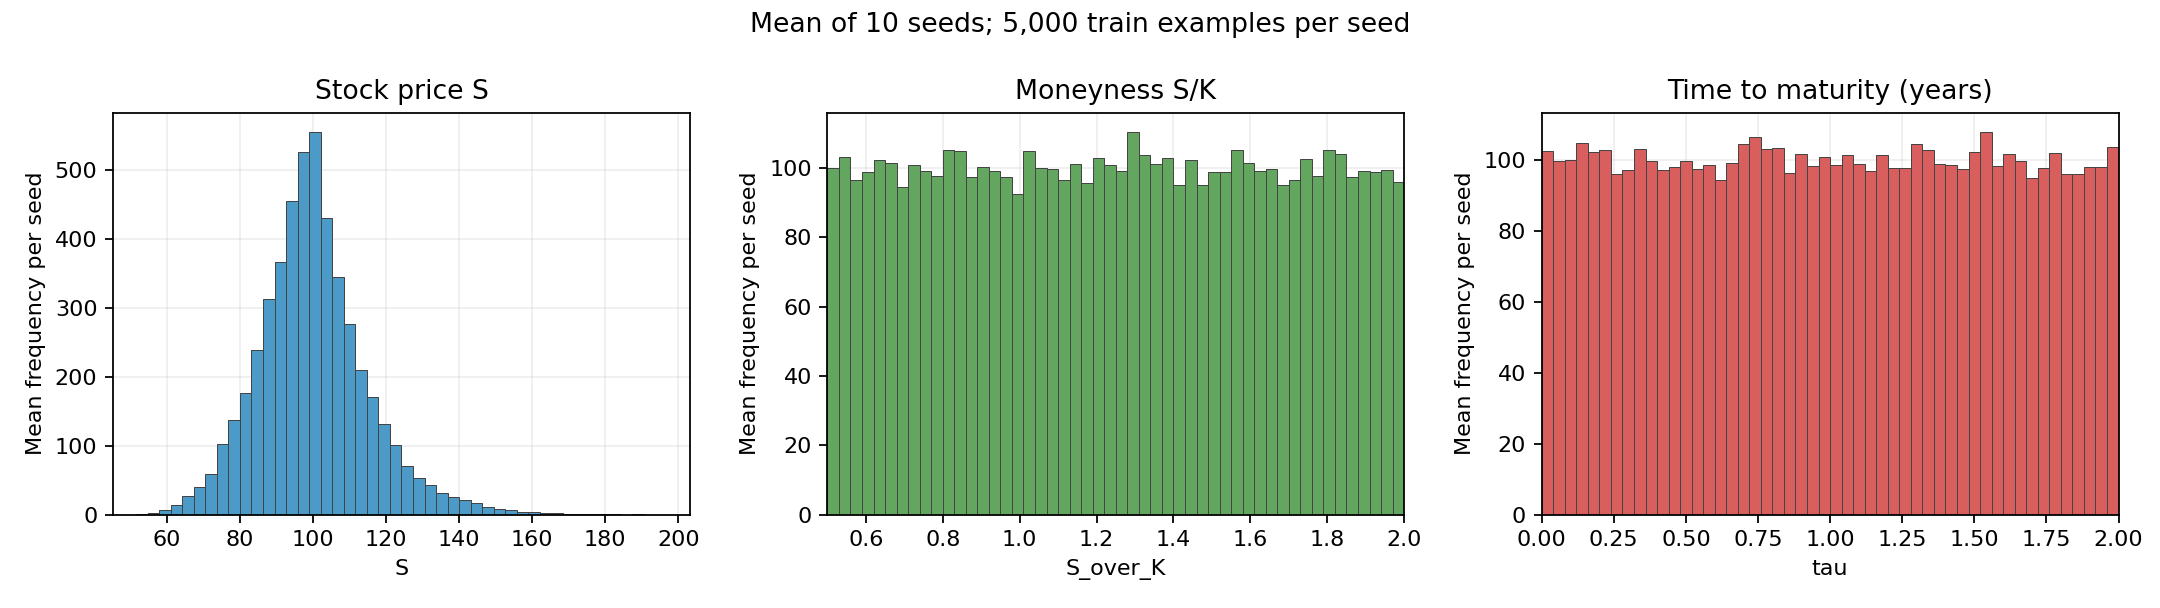

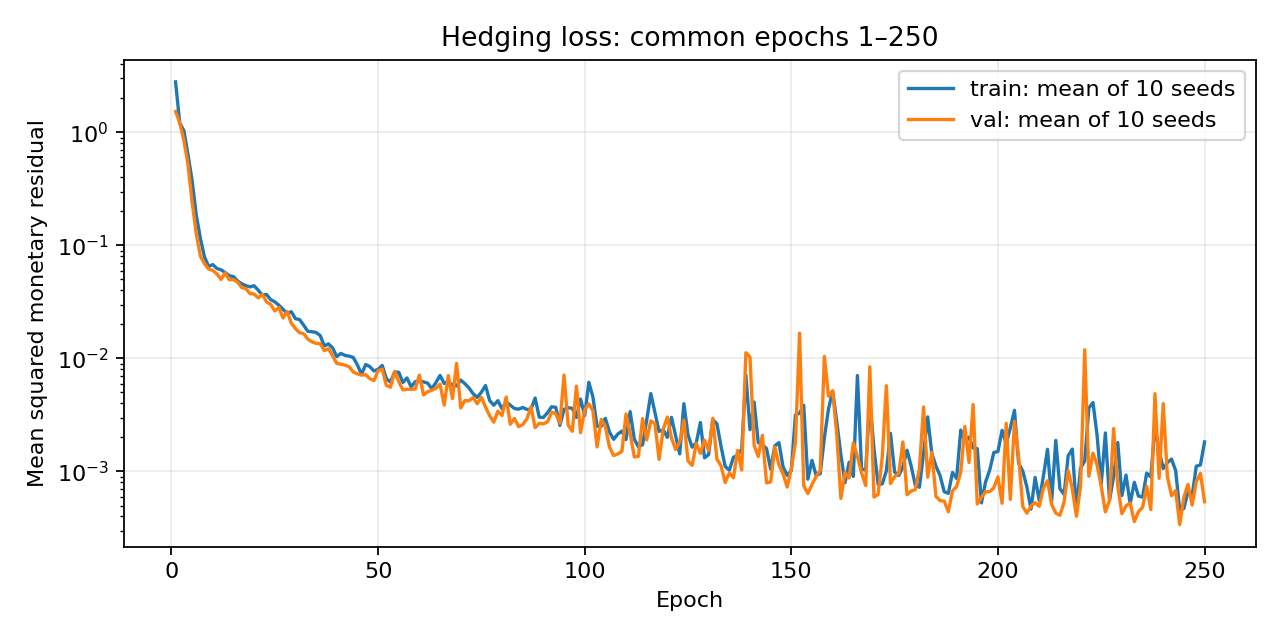

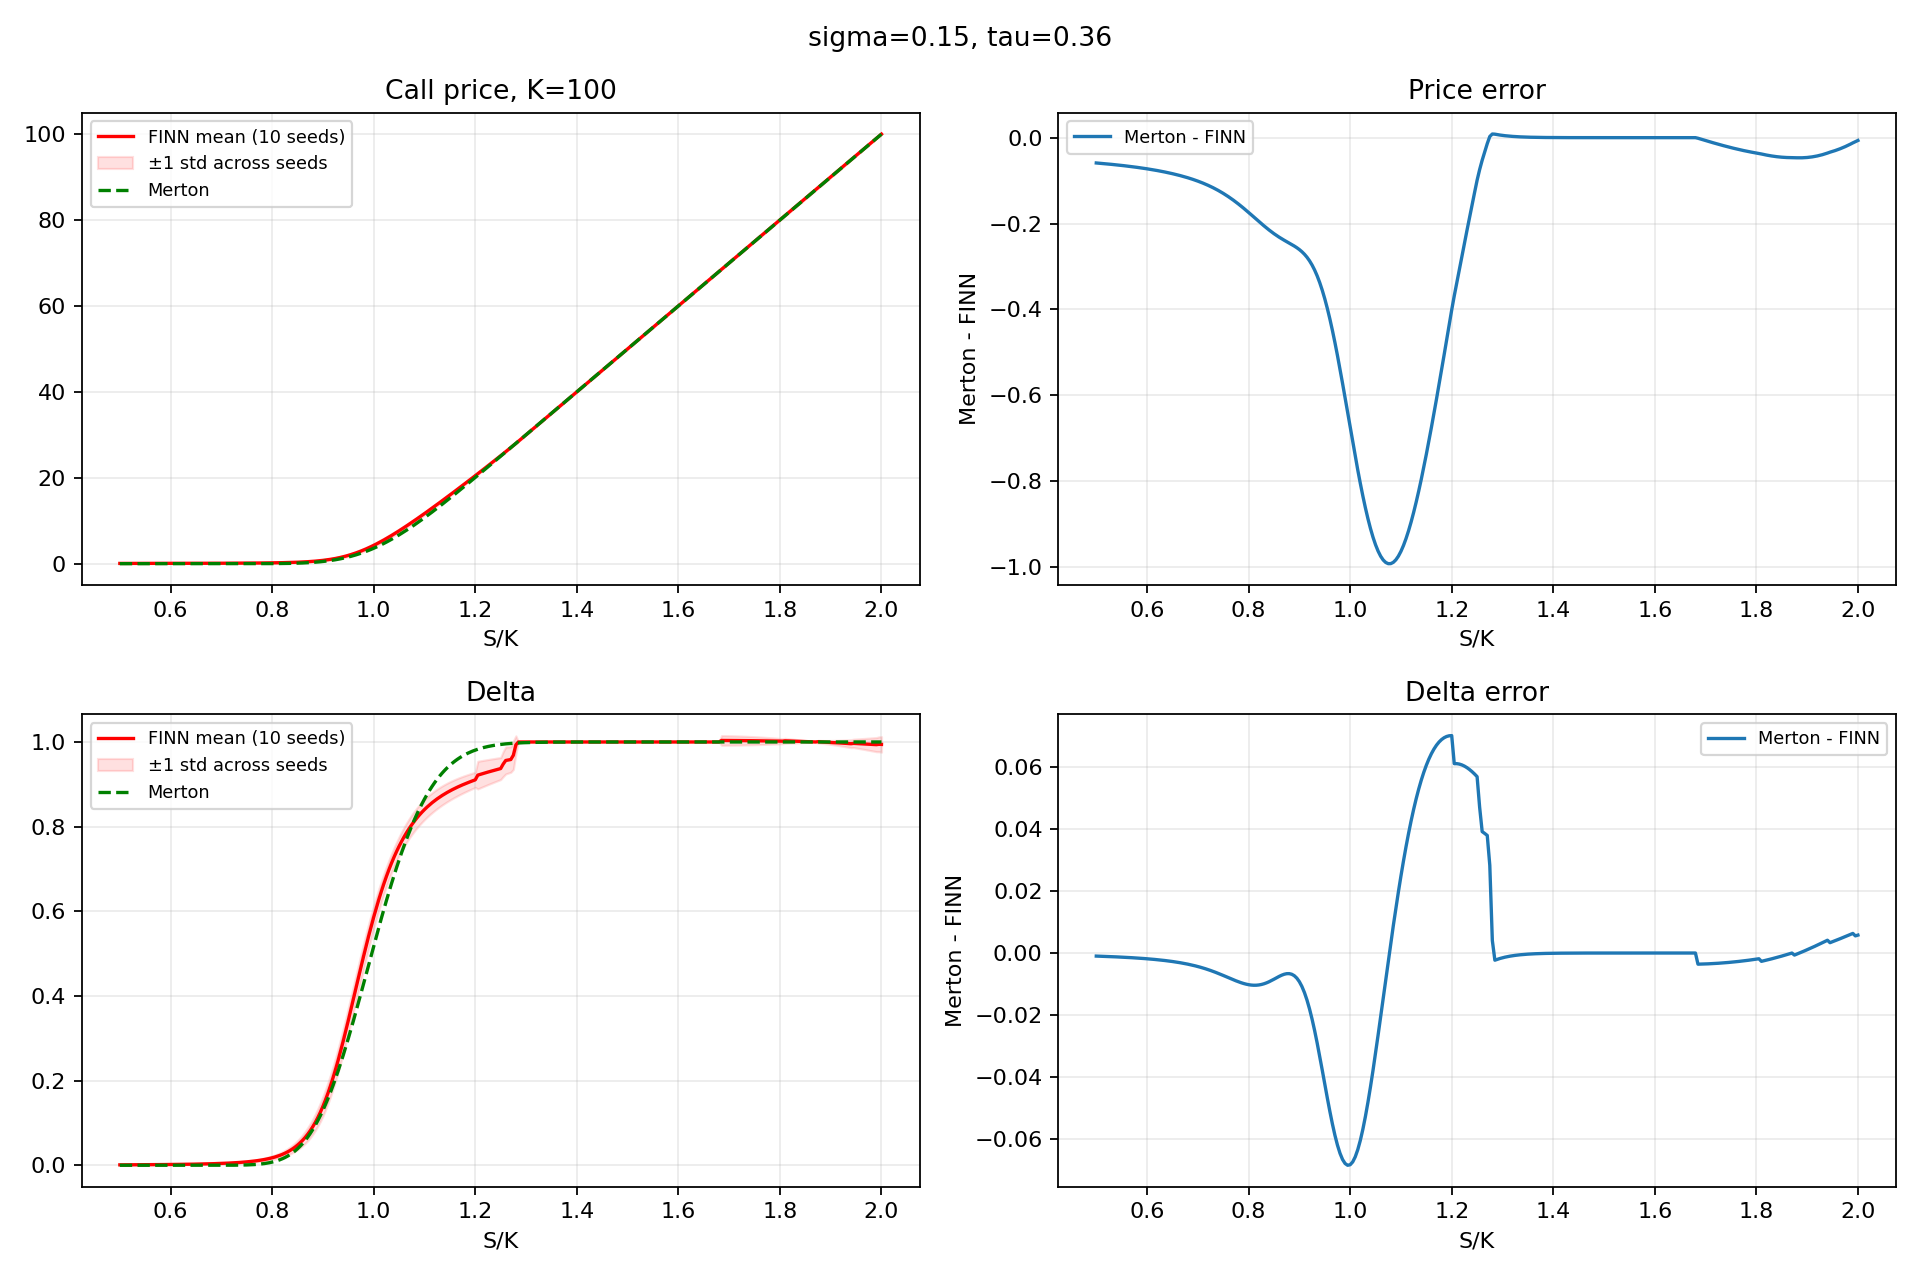

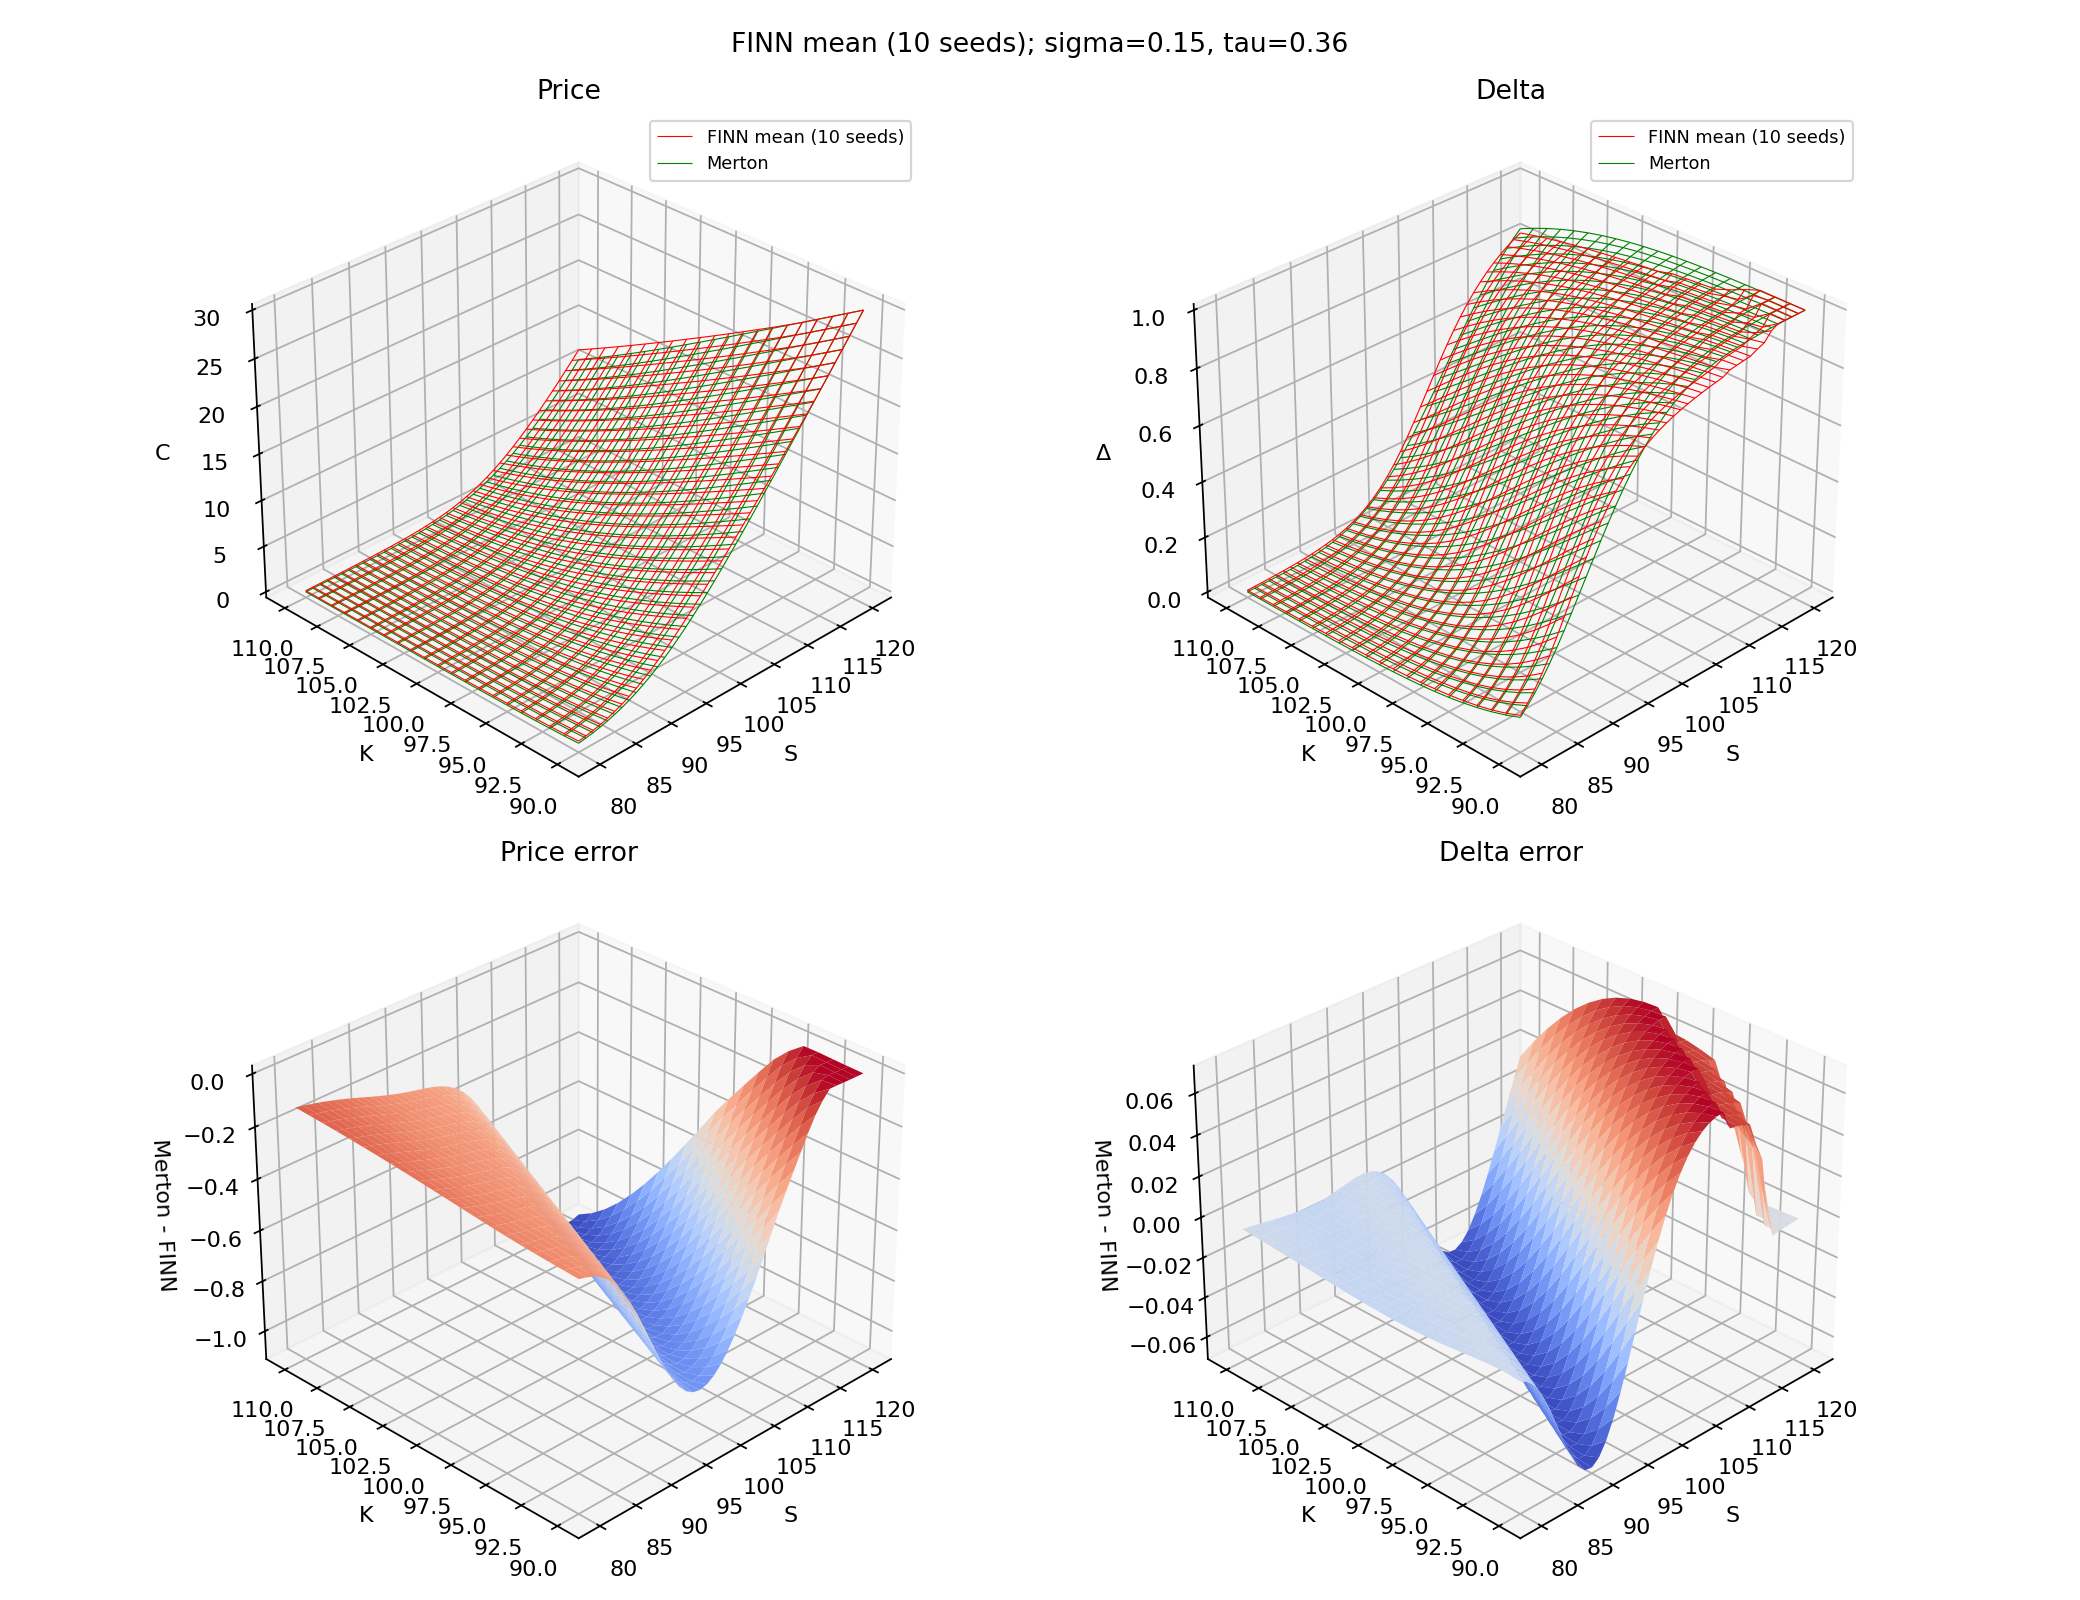

=== Средние графики λ=1: 10 seed, sigma=0.15, tau=0.36 ===


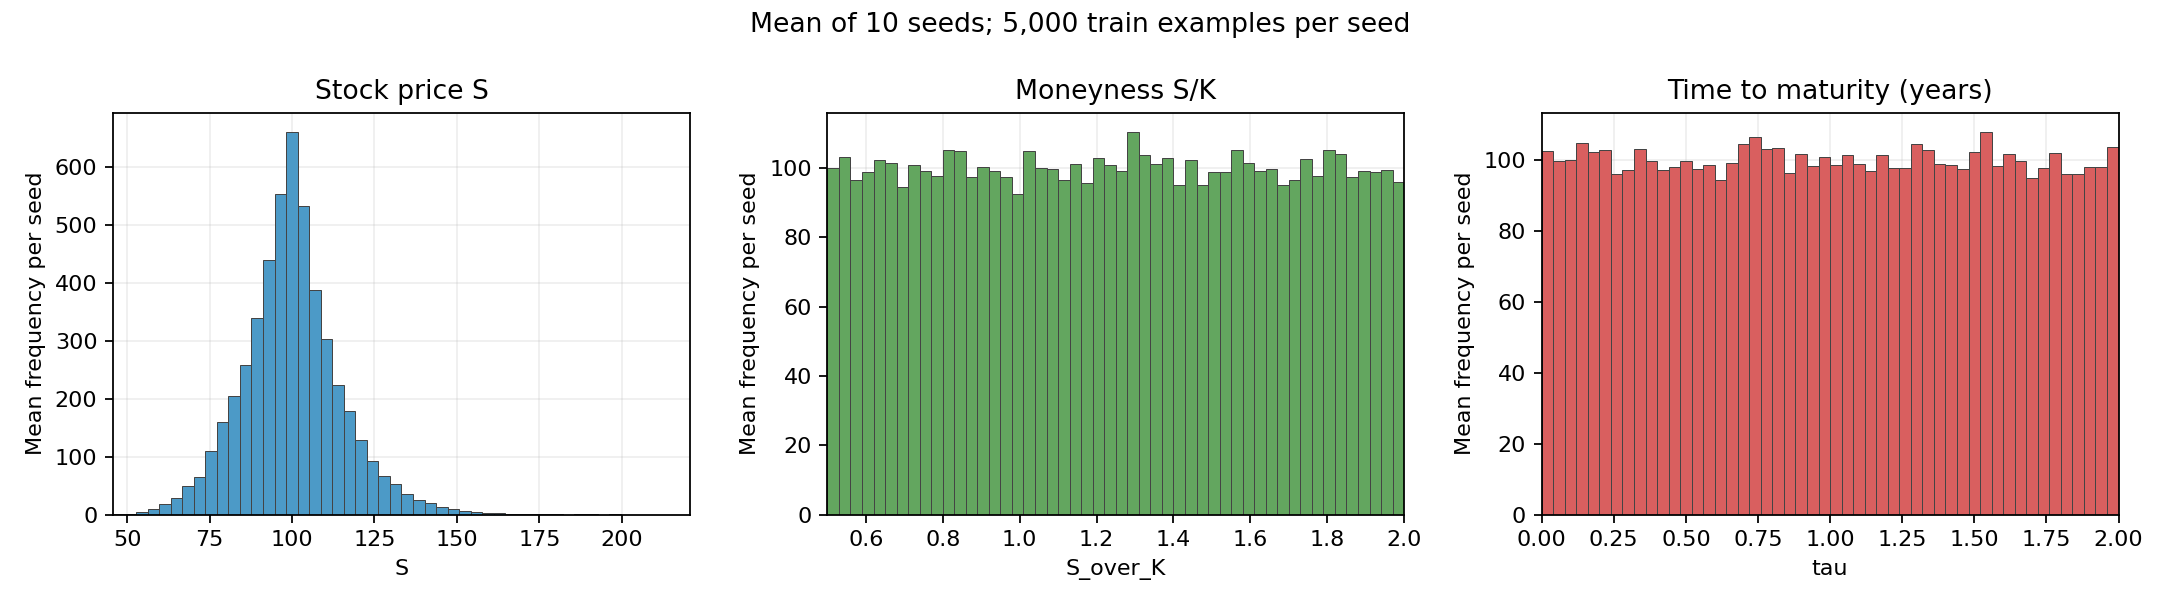

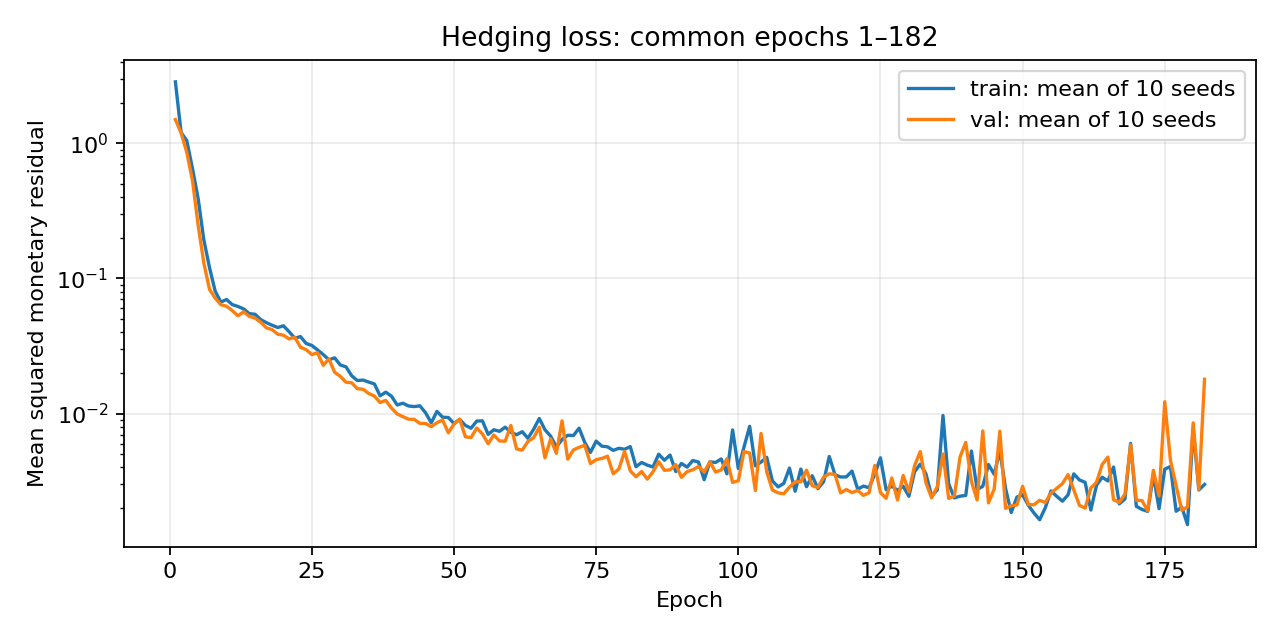

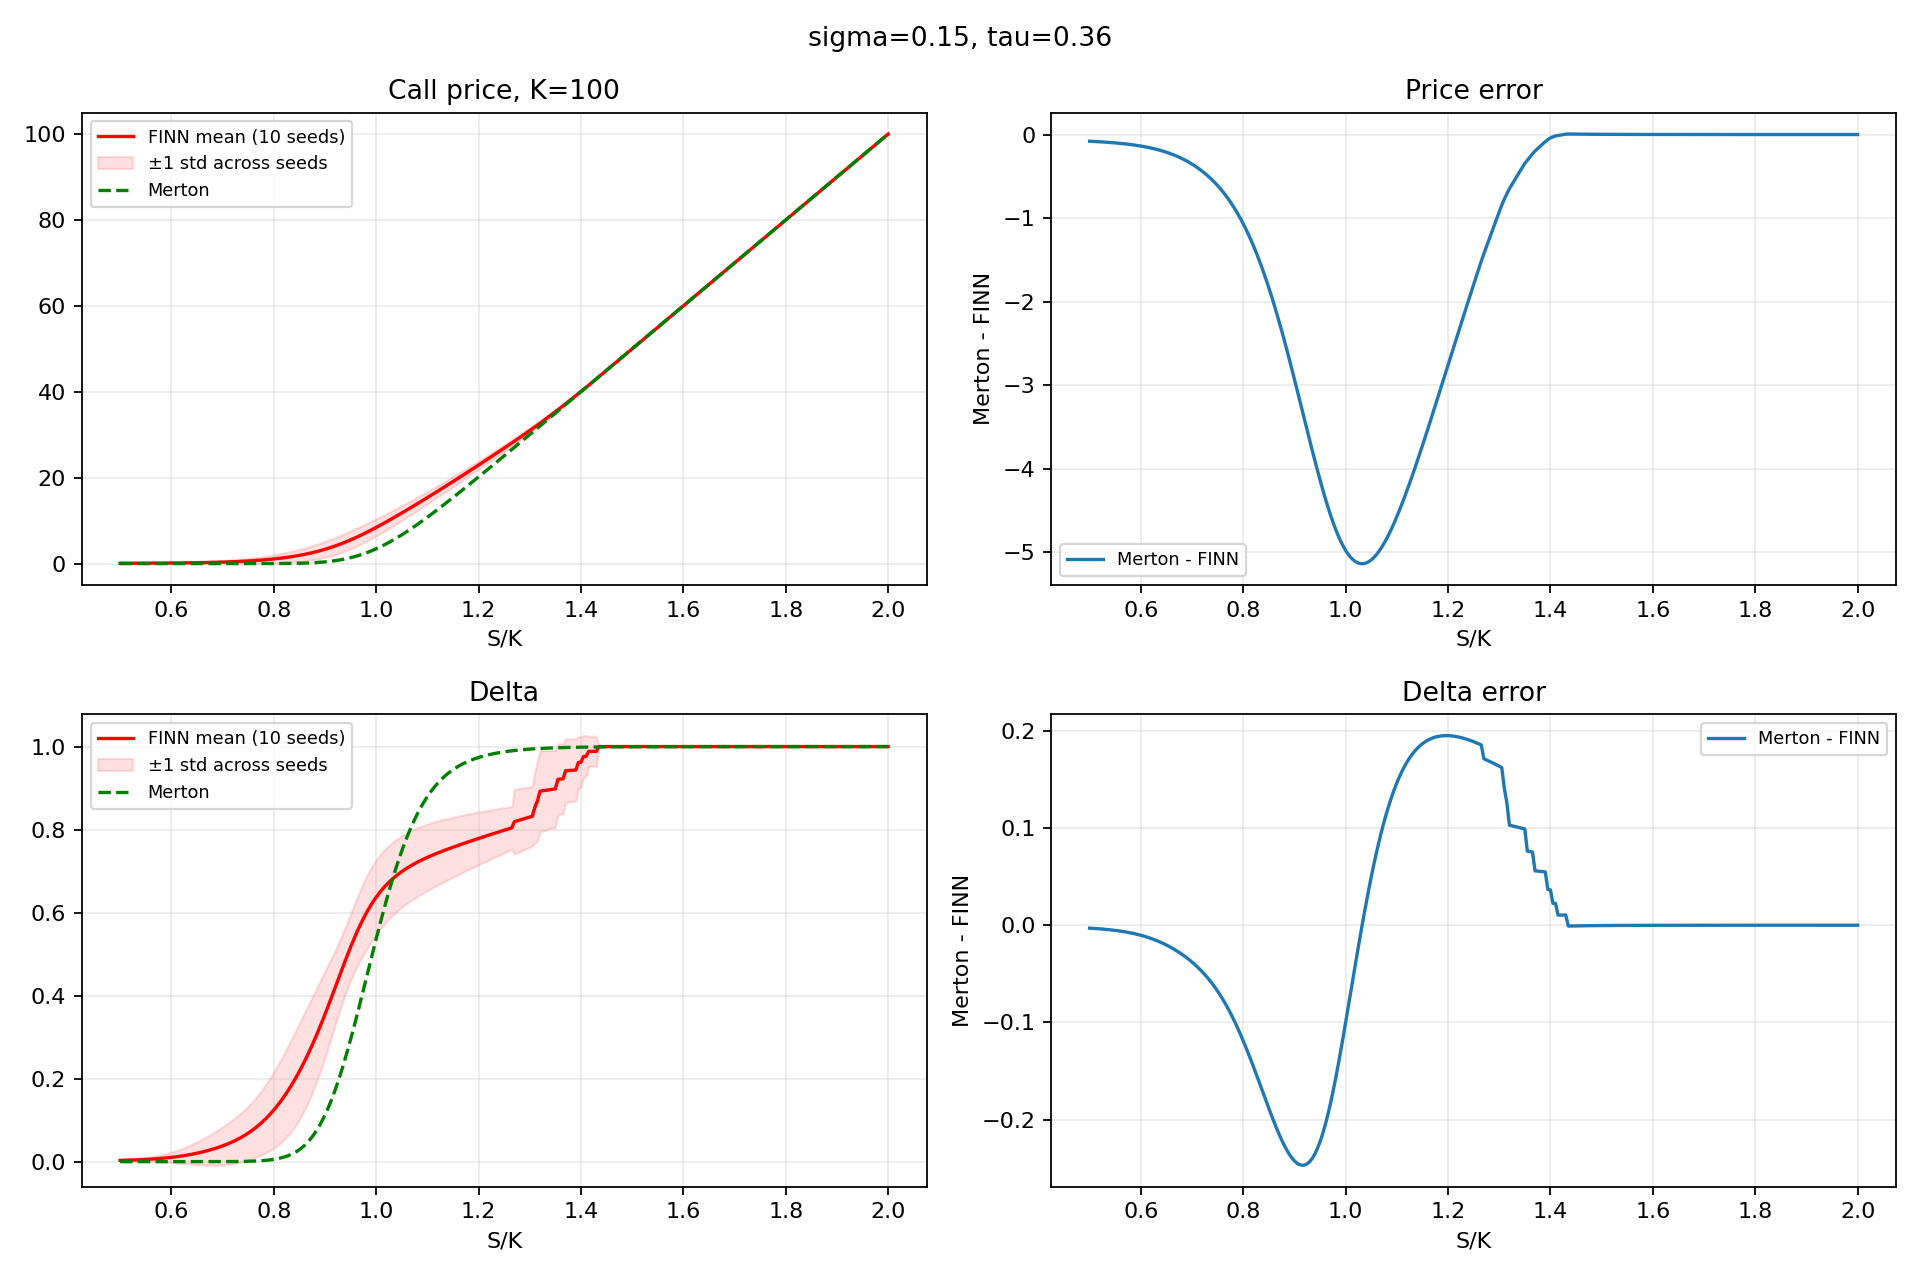

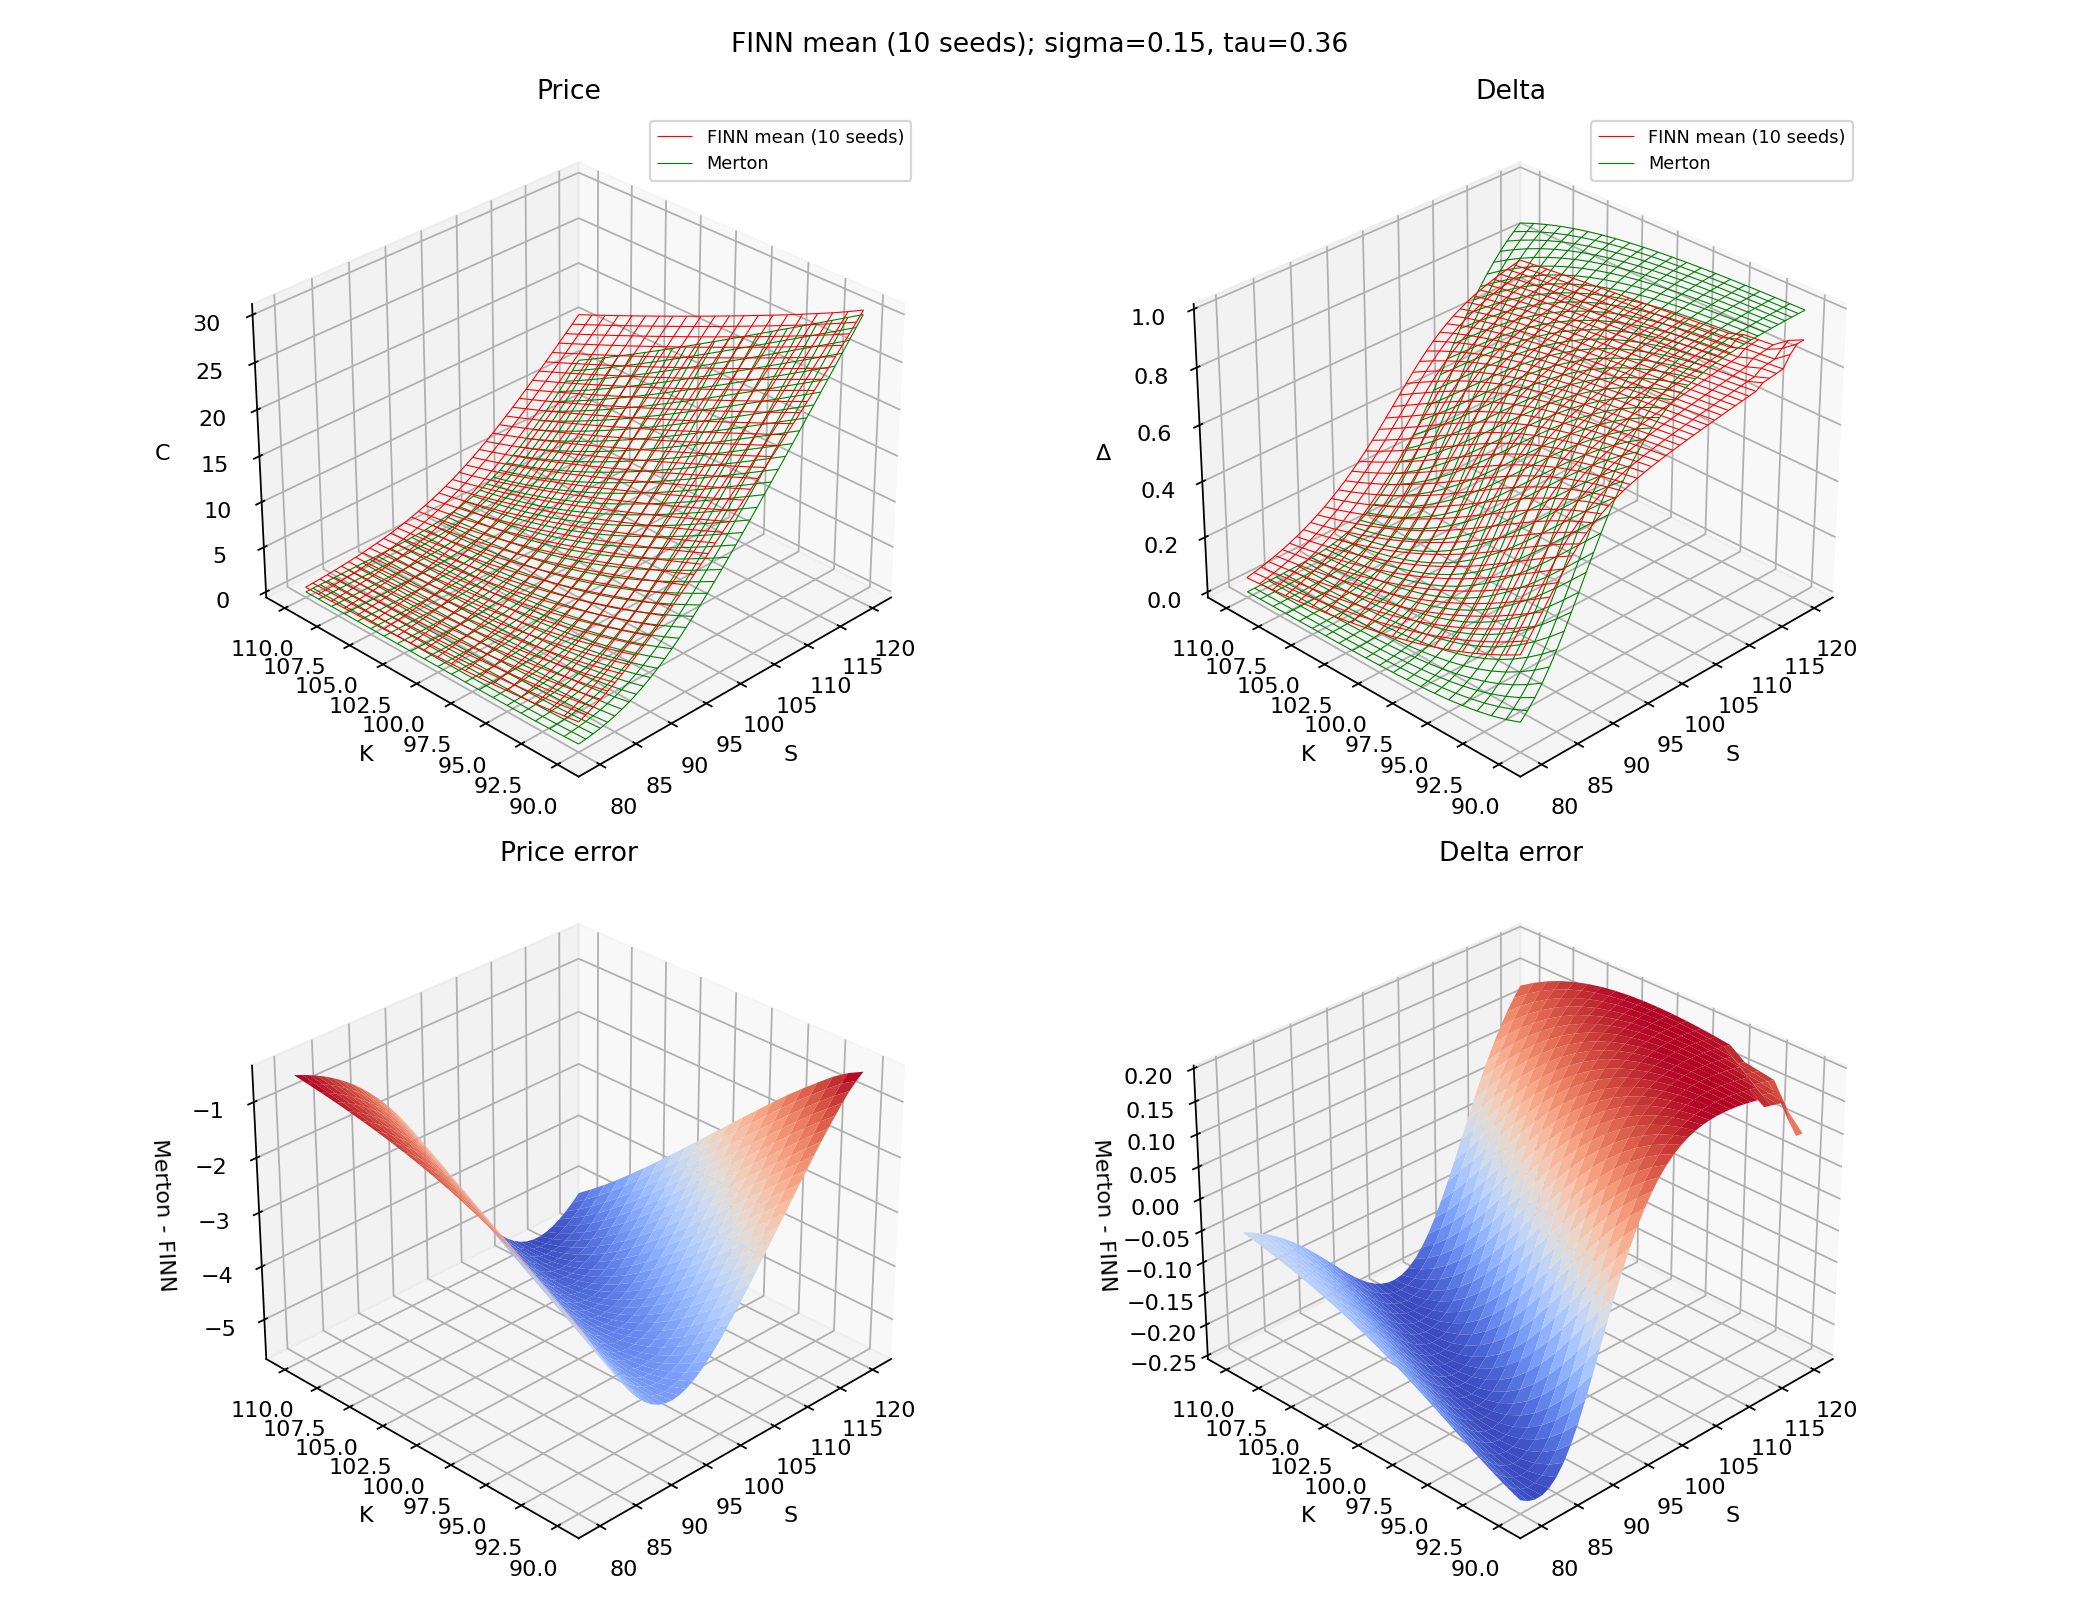

=== Средние графики λ=3: 10 seed, sigma=0.15, tau=0.36 ===


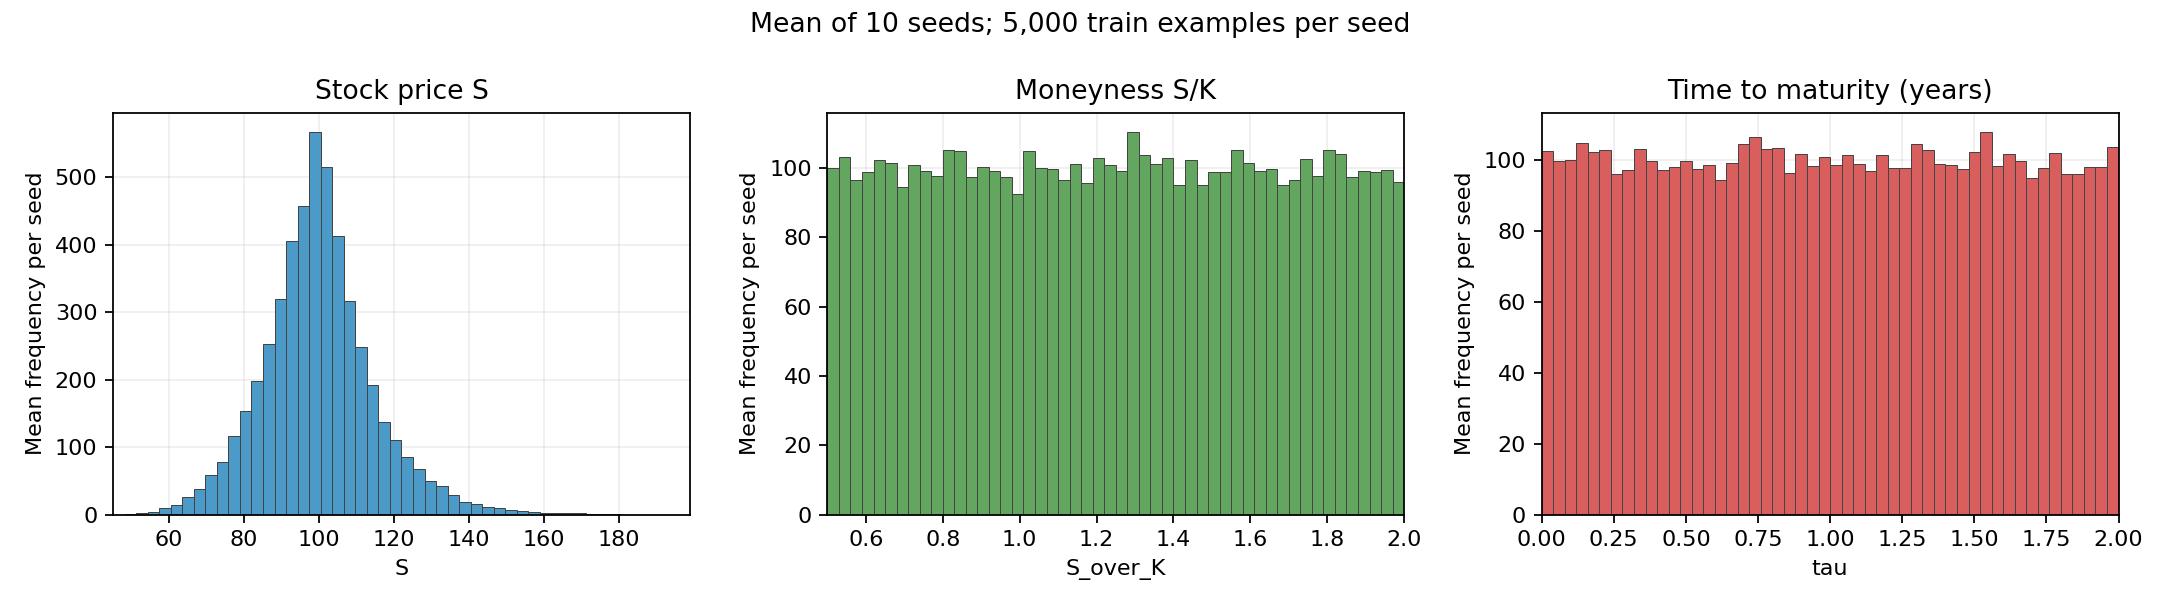

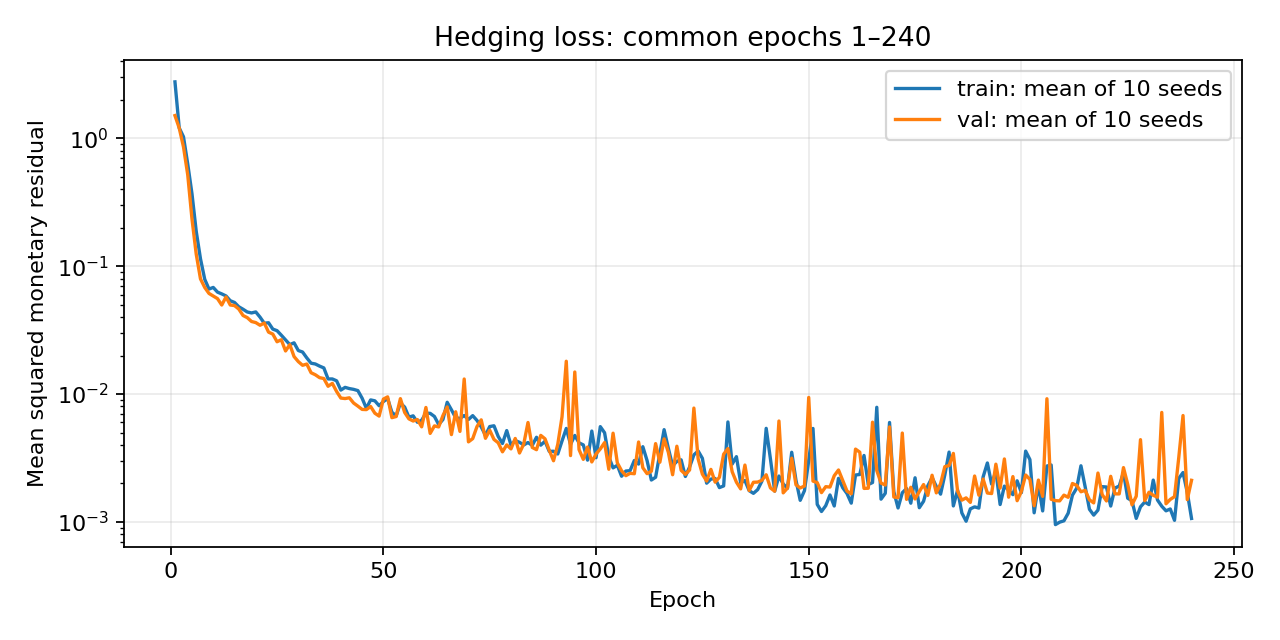

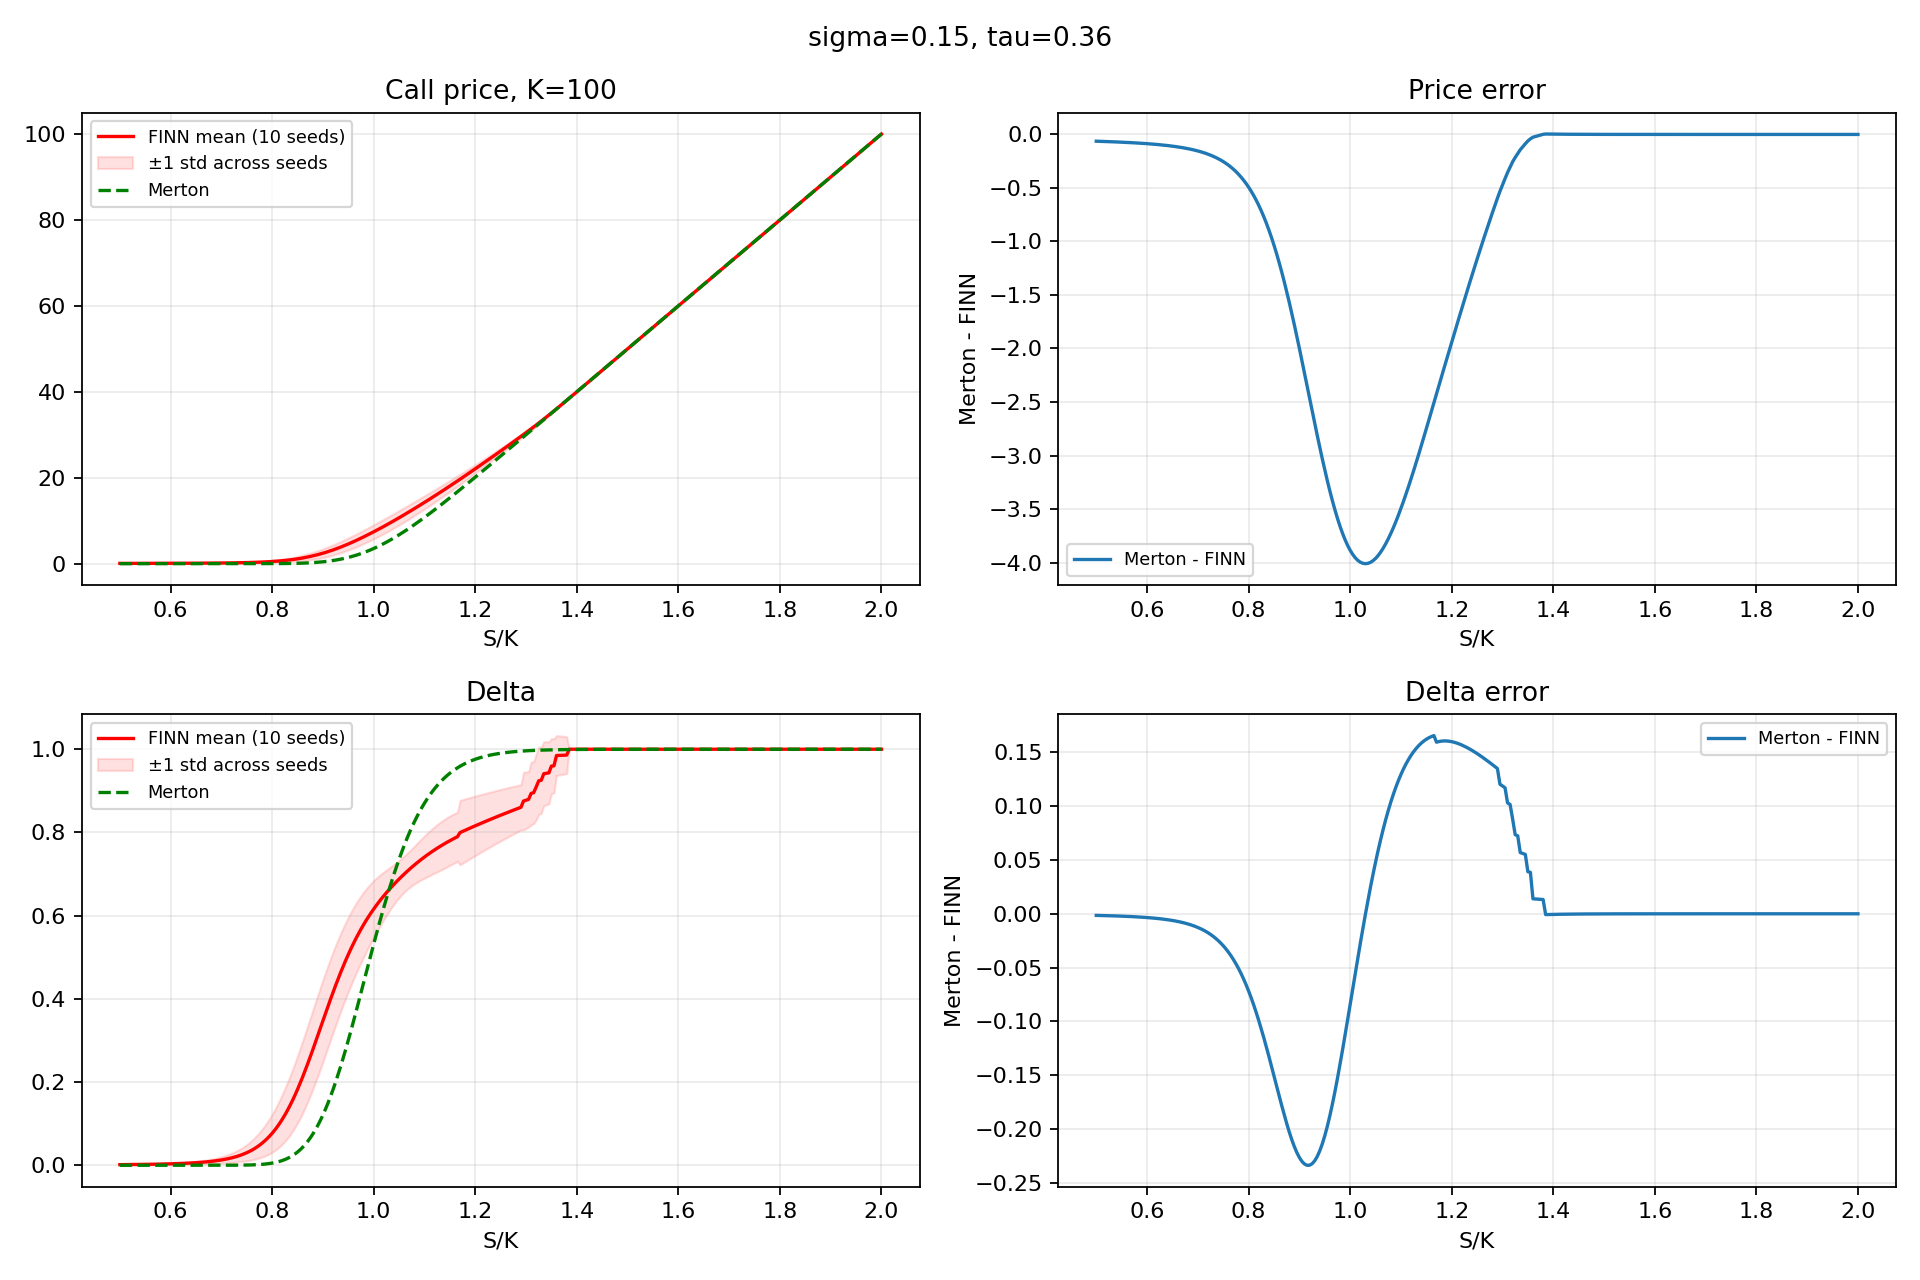

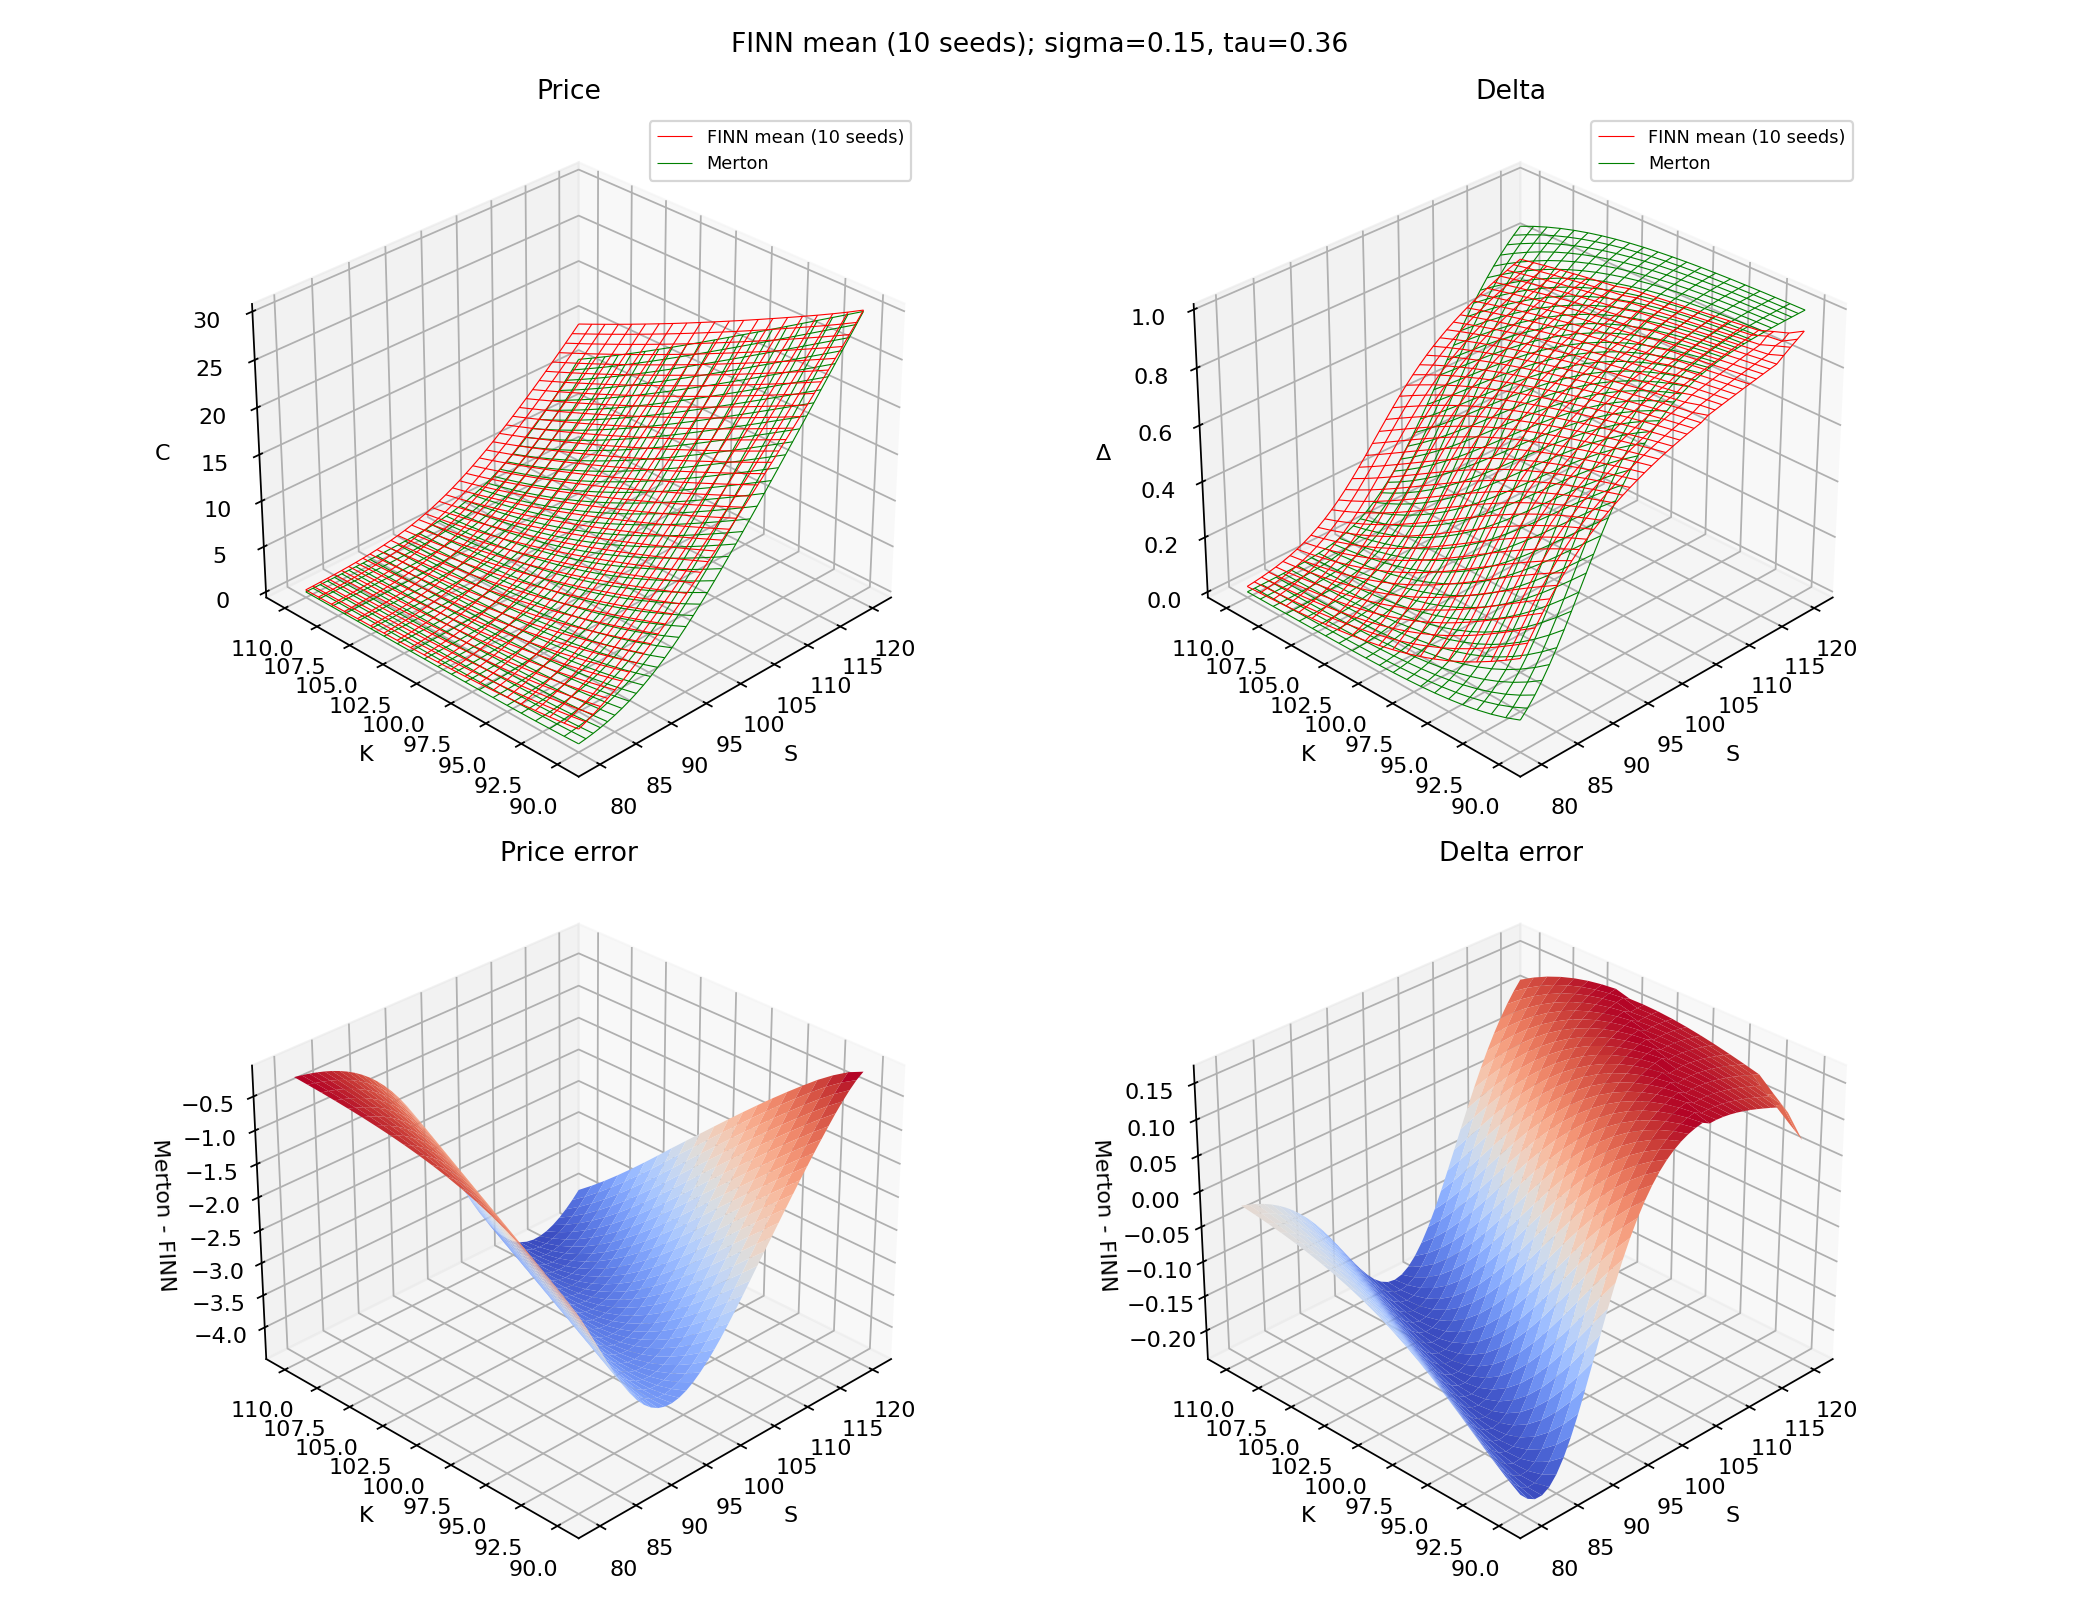

=== Средние графики λ=5: 10 seed, sigma=0.15, tau=0.36 ===


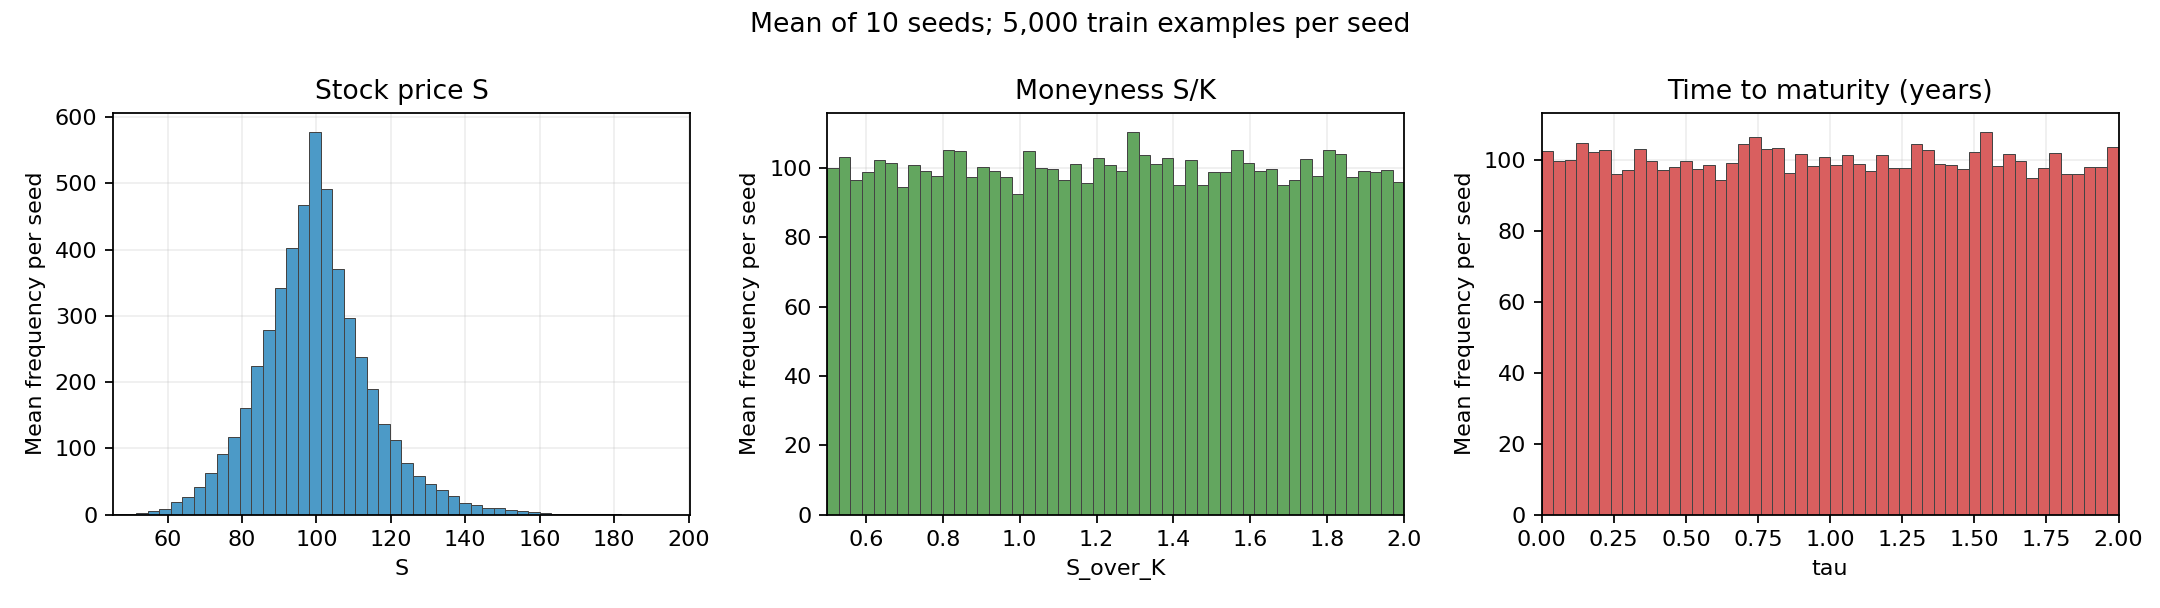

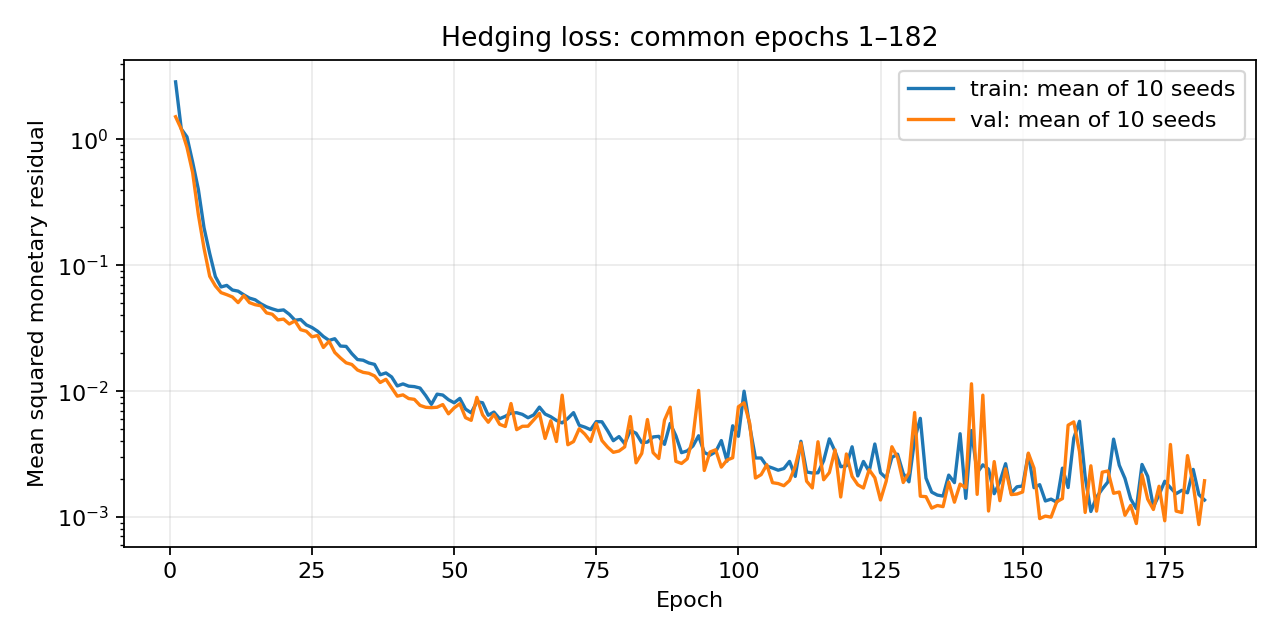

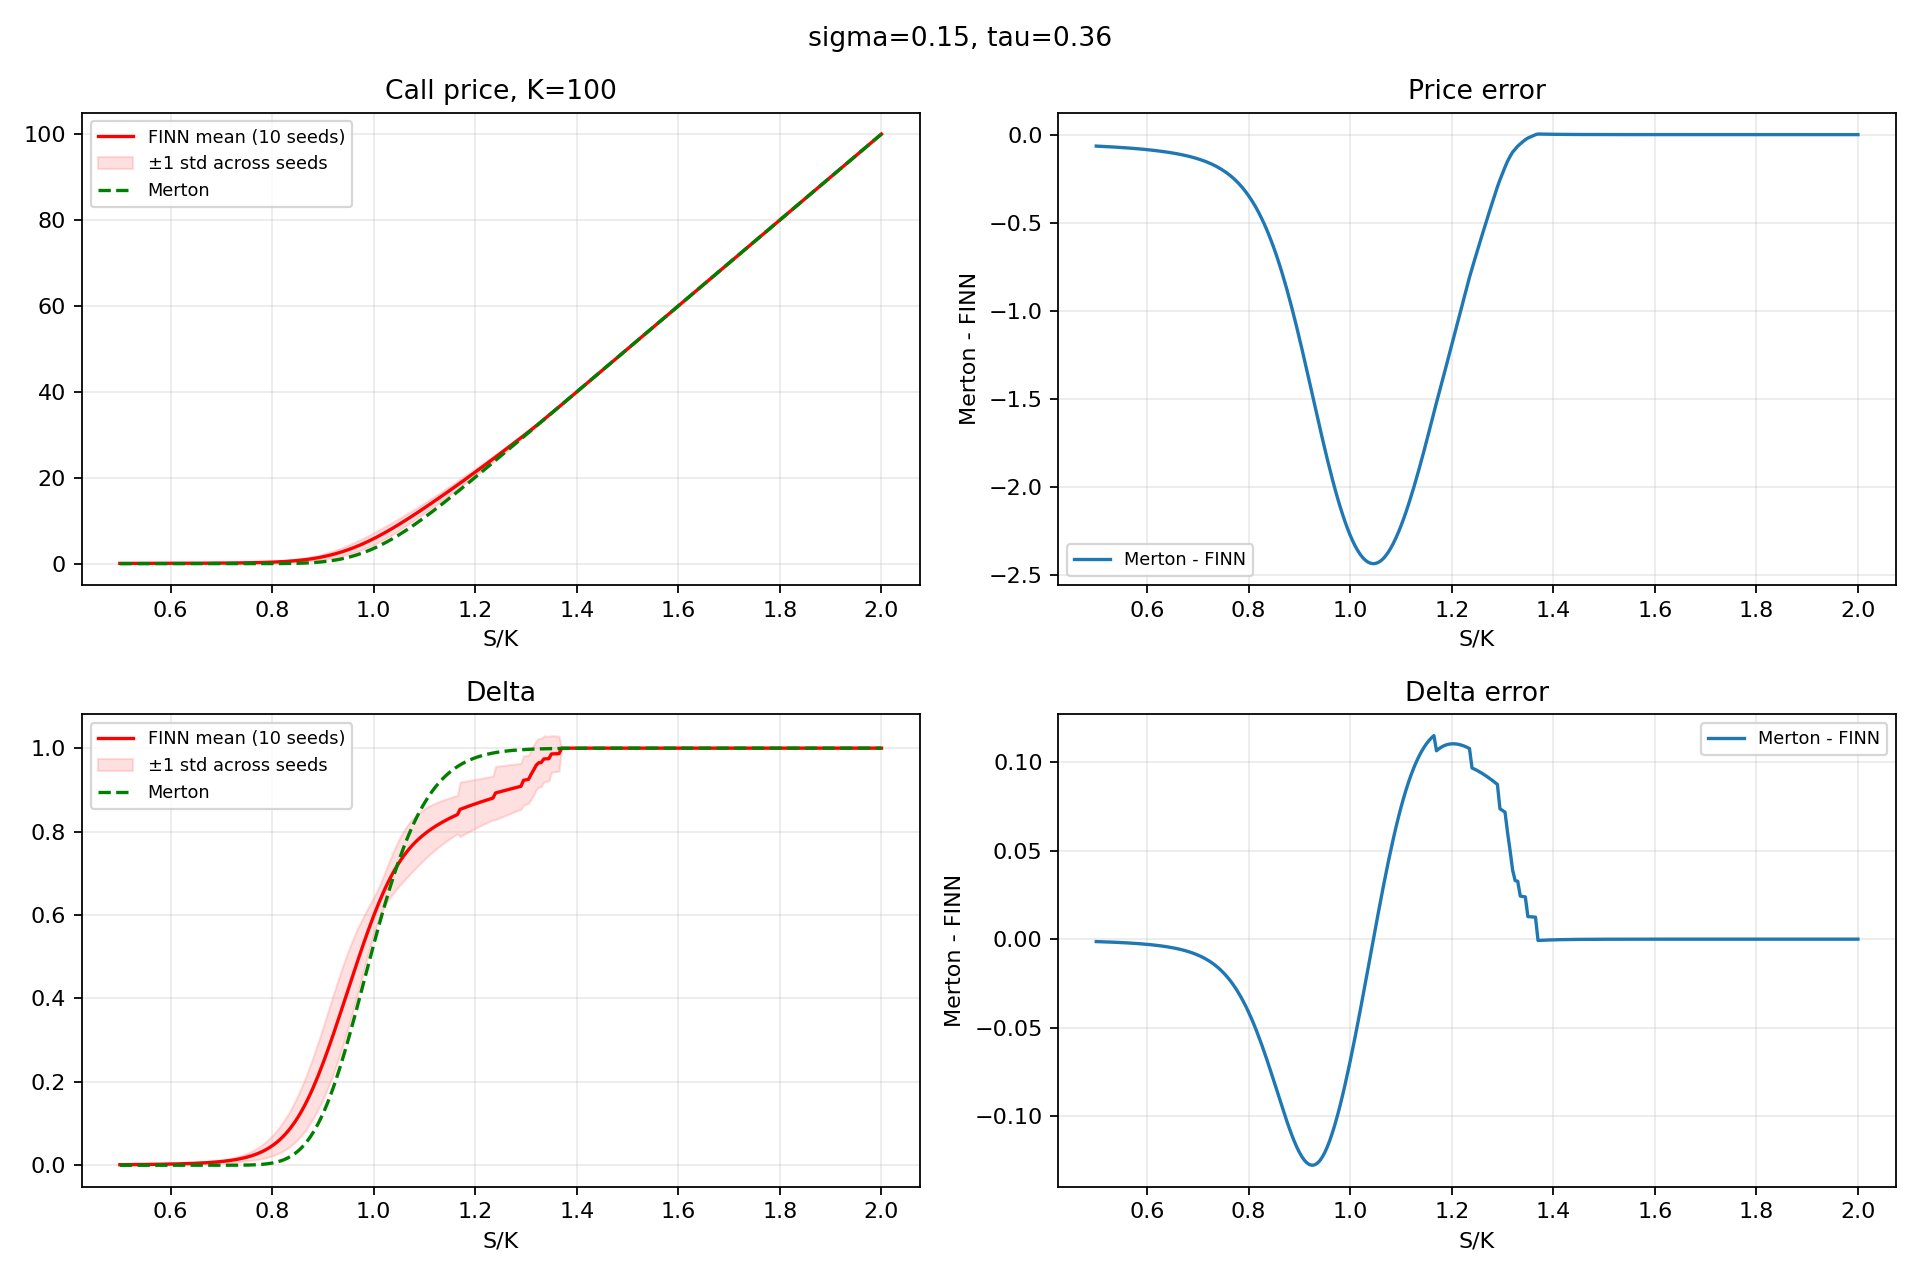

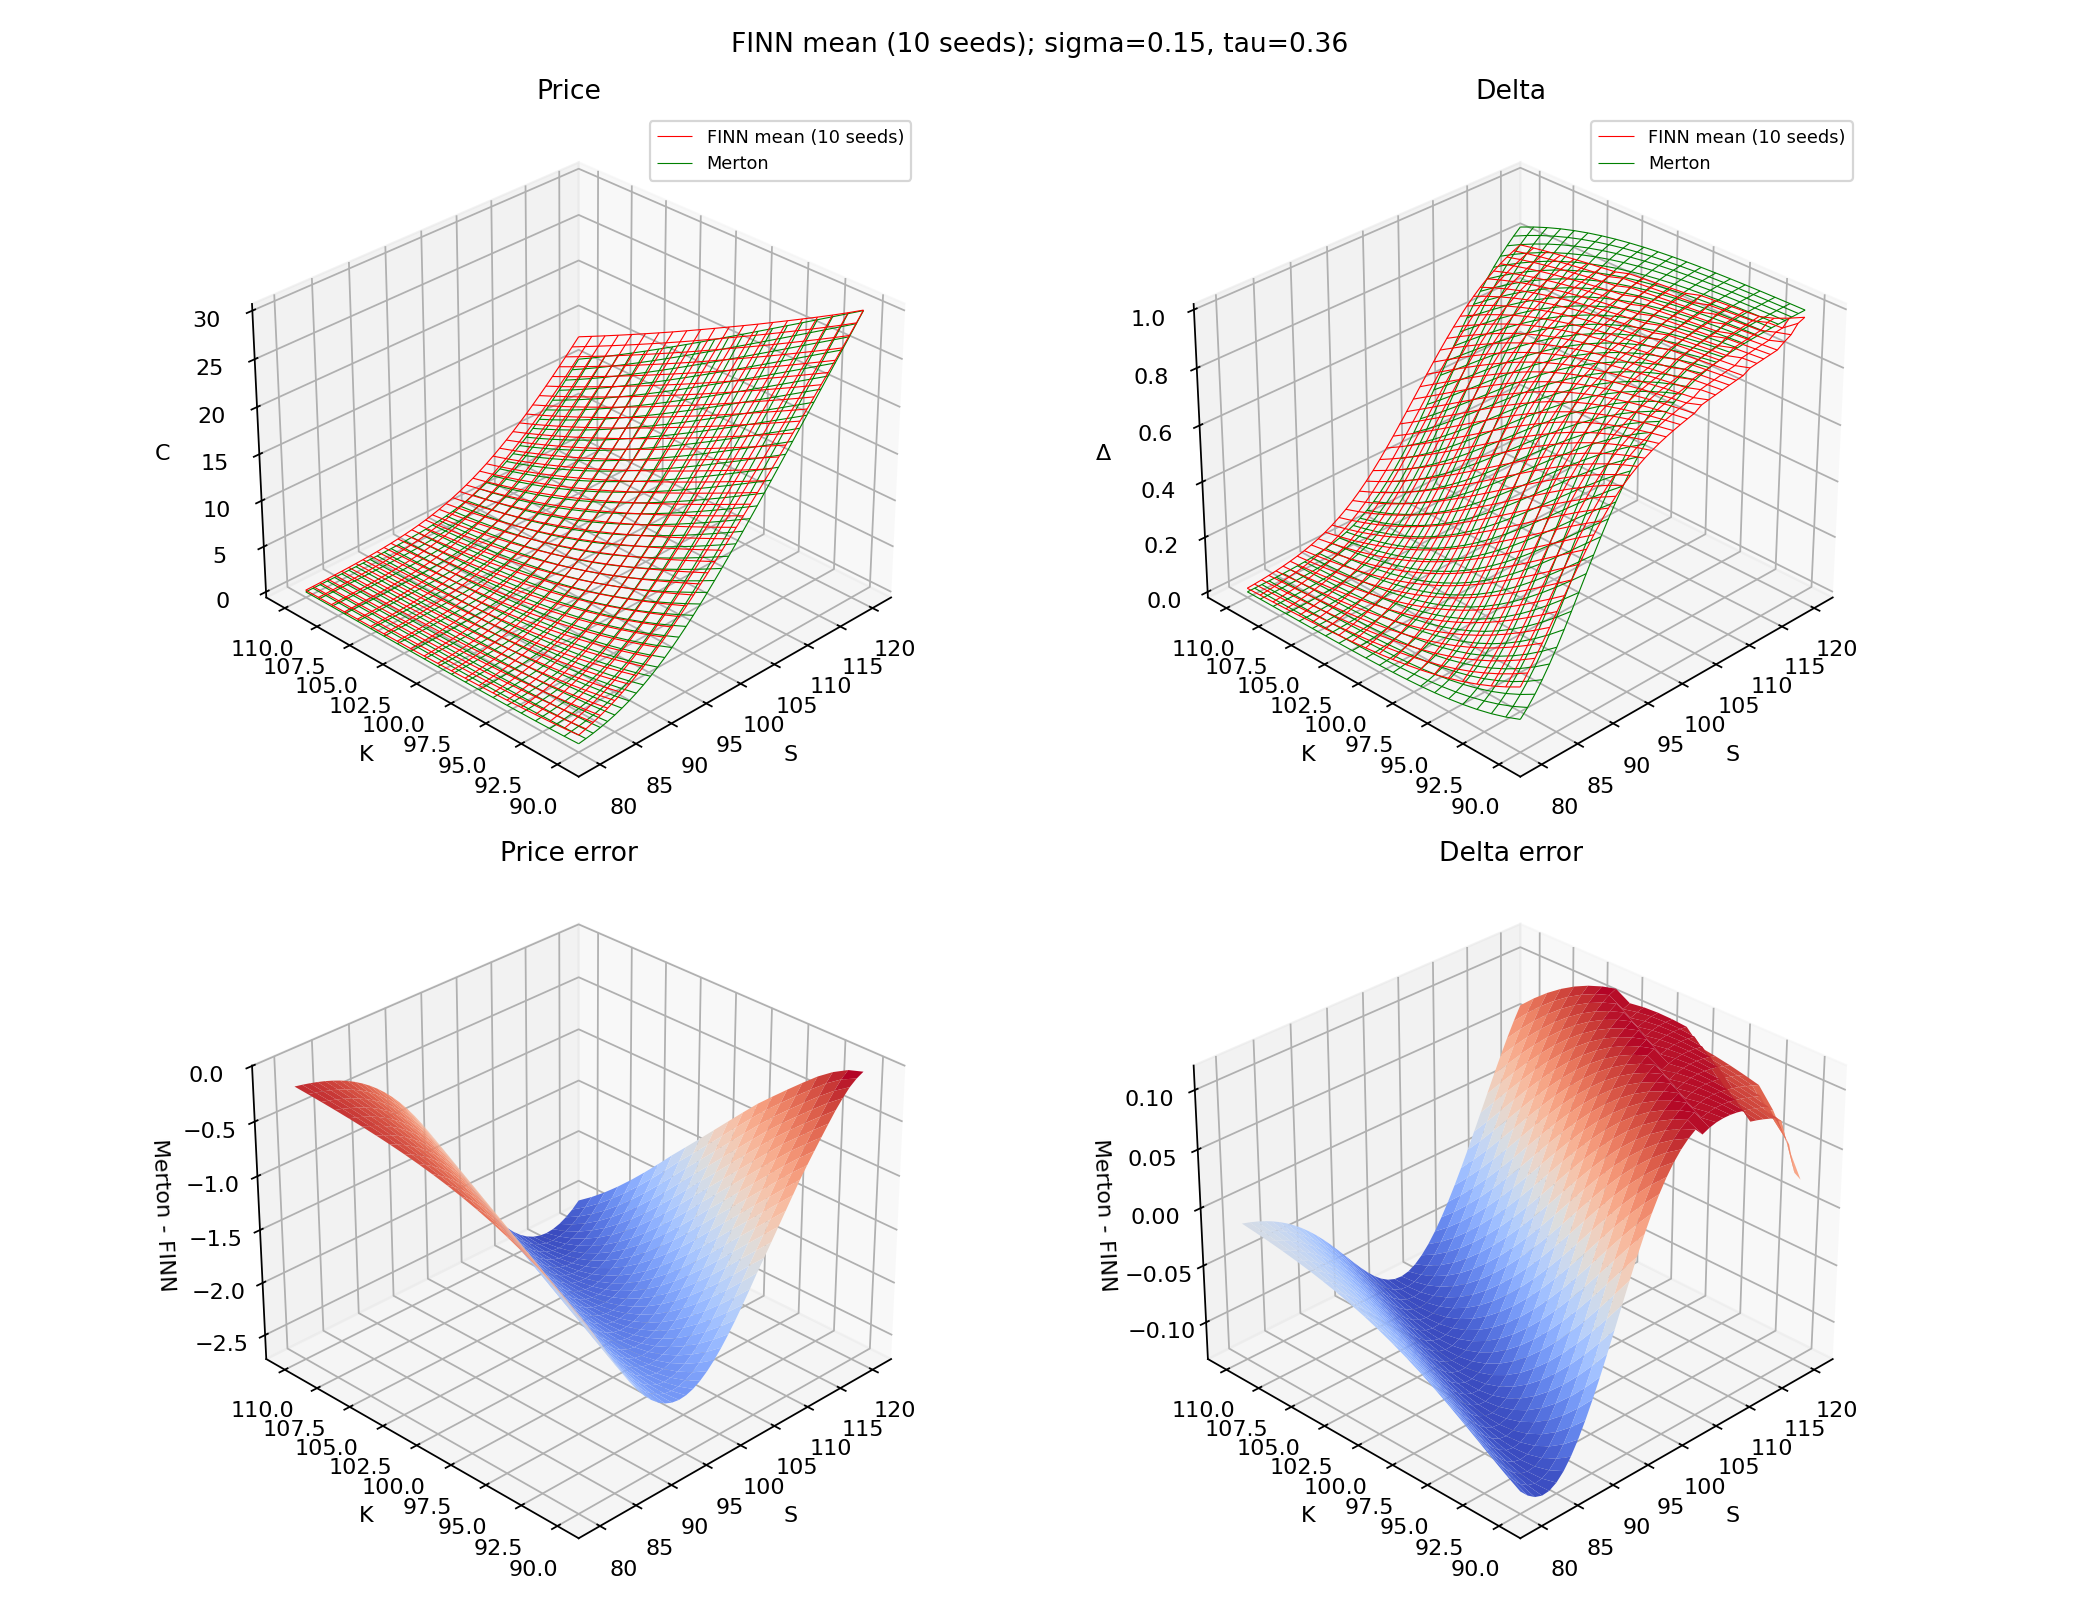

In [15]:
# Построение и отображение средних графиков по 10 seed для всех λ ∈ {0, 1, 3, 5}

if saved is None:
    for lmbd in lambda_levels:
        cfgs_lmbd = study_configs_by_lambda[lmbd]
        ref_cfg = next(c for c in cfgs_lmbd if c.sigma == base_cfg.surface_sigma and c.seed == base_cfg.seed)
        plot_directory = build_mean_plots(Path(out_by_lambda[lmbd]), cfgs_lmbd, ref_cfg, run_seeds)
        print(f"=== Средние графики λ={lmbd:g}: {len(run_seeds)} seed, sigma={ref_cfg.surface_sigma}, tau={ref_cfg.surface_tau} ===")
        for filename in ("training_distribution.png", "training.png", "comparison.png", "surfaces.png"):
            img_path = plot_directory / filename
            if img_path.is_file():
                display(Image(filename=str(img_path)))
else:
    print("Графики checkpoint сохранены в папке оценки:", out)


## 11. Экспорт артефактов серий и оптимизация папки outputs

Единое сохранение результатов исследования по всем $\lambda \in \{0, 1, 3, 5\}$ и подготовка к переносу на локальный компьютер:
1. **Веса нейросетей**: веса лучших моделей `best_model.pt` для всех сидов, уровней волатильности и интенсивностей скачков;
2. **Неусреднённые таблицы (`metrics_runs.csv`)**: подробная фиксация $\text{RMAD}$, $\text{RMSE}$, $\text{NMAD}$, $\text{MSE}$ по каждому `seed`;
3. **Сводные таблицы (`table1.csv`, `table9.csv`, `metrics_summary.csv`)**: средние значения и стандартные отклонения по стандарту статьи;
4. **Таблицы сопоставления со статьёй (`article_comparison.csv`)**;
5. **Очистка диска**: удаление промежуточных массивов выборок (`.npz`) и `last_model.pt` с сохранением `complete.json` для валидации чекпоинтов.


In [16]:
# Единое сохранение всех артефактов серий и очистка тяжёлых временных файлов

def cleanup_temporary_files(directory: Path, configurations: list[Config]) -> int:
    """Удаление только тяжёлых временных массивов выборок после построения всех графиков,
    сохраняя complete.json и метаданные для корректной работы completed_report."""
    cleaned = 0
    for cfg in configurations:
        fld = run_directory(directory, cfg)
        for temp_name in ("train_samples.npz", "validation_samples.npz", "last_model.pt"):
            temp_file = fld / temp_name
            if temp_file.exists():
                temp_file.unlink()
                cleaned += 1
    return cleaned

if saved is None:
    total_cleaned = 0
    print("=" * 70)
    print("Результаты серий Мертона сохранены:")
    for lmbd in lambda_levels:
        out_dir = Path(out_by_lambda[lmbd])
        canon_rows = [
            {k: r[k] for k in ("quantity", "metric", "article", "current", "difference", "digits")}
            for r in comp_rows_by_lambda[lmbd]
        ]
        write_csv(out_dir / "article_comparison.csv", canon_rows)
        total_cleaned += cleanup_temporary_files(out_dir, study_configs_by_lambda[lmbd])
        print(f"  - λ = {lmbd:g}: {out_dir} ({len(study_configs_by_lambda[lmbd])} моделей best_model.pt)")
    if total_cleaned > 0:
        print(f"  - Удалено временных файлов (.npz / last_model.pt): {total_cleaned} шт.")
    print("=" * 70)
    print("Перенос на Mac доступен через: ./download_vkr_results.command")


Результаты серий Мертона сохранены:
  - λ = 0: /content/VKR/outputs/merton_call_2053cc57e1be9b60 (30 моделей best_model.pt)
  - λ = 1: /content/VKR/outputs/merton_call_534898fa7430d394 (30 моделей best_model.pt)
  - λ = 3: /content/VKR/outputs/merton_call_3edc1bacf0aa4220 (30 моделей best_model.pt)
  - λ = 5: /content/VKR/outputs/merton_call_8082d1f342b86542 (30 моделей best_model.pt)
  - Удалено временных файлов (.npz / last_model.pt): 360 шт.
Перенос на Mac доступен через: ./download_vkr_results.command


## 12. Сводное сопоставление результатов при $\lambda \in \{0, 1, 3, 5\}$

Анализ влияния неполноты рынка и пуассоновских скачков в модели Мертона на способность FINN (`2 → 50 → 50 → 1`) оценивать и дельта-хеджировать европейский колл-опцион ($r=0$).
Во всех четырёх сериях суммарная годовая дисперсия зафиксирована на уровне $\sigma^2$ ($\sigma \in \{0.125, 0.15, 0.175\}$, по 10 seed `42–51` на каждую $\sigma$, итого 30 обучений на каждую $\lambda$ и 120 обучений суммарно):
- при $\lambda = 0$: чисто диффузионный рынок Блэка–Шоулза (GBM, санити-чек);
- при $\lambda \in \{1, 3, 5\}$: годовой вклад скачков $\lambda(\mu_J^2 + \sigma_J^2) \equiv 0.008 = \text{const}$, где $\mu_J(\lambda) = -0.04/\sqrt{\lambda}$, $\sigma_J(\lambda) = 0.08/\sqrt{\lambda}$, а диффузионная компонента $\sigma_{\text{diff}} = \sqrt{\sigma^2 - 0.008}$.

Ниже представлены 6 аналитических срезов по всем $\lambda \in \{0, 1, 3, 5\}$:
1. **Интегральные ошибки (RMAD, RMSE, NMAD, MSE)** и скорость деградации архитектуры с ростом $\lambda$.
2. **Распределение ошибки по Moneyness ($S/K$)**: глубоко OTM, ATM и глубоко ITM.
3. **Чувствительность к сроку до экспирации ($\tau \in [0.24, 0.48]$)**.
4. **Асимптота функции потерь (Unhedgeable Risk)** при сходимости обучения.
5. **Поверхность / улыбка подразумеваемой волатильности (IV Smile)** Блэка–Шоулза.
6. **Гладкость Дельты ($\Delta$)** в окрестности страйка $K=100$.


In [17]:
# Загрузка сводных таблиц по 4 сериям Мертона (λ = 0, 1, 3, 5) из папки outputs
studies = {}
for lmbd in lambda_levels:
    folder = Path(out_by_lambda[lmbd]) if "out_by_lambda" in globals() else (results_root / reuse_studies[lmbd])
    plan_file = folder / "study.json"
    if not plan_file.is_file():
        continue
    plan = json.loads(plan_file.read_text(encoding="utf-8"))
    cfg0 = plan["configurations"][0]
    studies[float(lmbd)] = {"dir": folder, "cfg": cfg0, "plan": plan}

LAMBDAS = sorted(studies)
COLORS = {0.0: "#2E7D32", 1.0: "#D32F2F", 3.0: "#F57C00", 5.0: "#1976D2"}
print("Загружены серии Мертона для λ:", LAMBDAS)
for lmbd in LAMBDAS:
    c = studies[lmbd]["cfg"]
    jv = lmbd * (c["jump_log_mean"]**2 + c["jump_log_std"]**2)
    print(f"  λ={lmbd:g}: {studies[lmbd]['dir'].name}, "
          f"μ_J={c['jump_log_mean']:.5f}, σ_J={c['jump_log_std']:.5f}, λ(μ_J²+σ_J²)={jv:.4f}")


Загружены серии Мертона для λ: [0.0, 1.0, 3.0, 5.0]
  λ=0: merton_call_2053cc57e1be9b60, μ_J=-0.04000, σ_J=0.08000, λ(μ_J²+σ_J²)=0.0000
  λ=1: merton_call_534898fa7430d394, μ_J=-0.04000, σ_J=0.08000, λ(μ_J²+σ_J²)=0.0080
  λ=3: merton_call_3edc1bacf0aa4220, μ_J=-0.02309, σ_J=0.04619, λ(μ_J²+σ_J²)=0.0080
  λ=5: merton_call_8082d1f342b86542, μ_J=-0.01789, σ_J=0.03578, λ(μ_J²+σ_J²)=0.0080


### 12.1 Интегральные ошибки (RMAD, RMSE, NMAD, MSE) в зависимости от $\lambda$

Сравнение средних метрик по всей тестовой выборке (3 уровня $\sigma \in \{0.125, 0.150, 0.175\} \times 7$ сроков $\tau \times 10$ seed = 210 оценок на каждую $\lambda$).


Величина,Метрика,Статья (BSM),λ = 0 (расх.),λ = 1 (расх.),λ = 3 (расх.),λ = 5 (расх.)
Цена,"RMAD, %",3.27,5.34 (+2.07),35.24 (+31.97),25.64 (+22.37),15.98 (+12.71)
Цена,"RMSE, %",2.76,4.19 (+1.43),25.96 (+23.20),19.43 (+16.67),12.15 (+9.39)
Цена,"NMAD, %",0.867,0.880 (+0.013),5.812 (+4.945),4.251 (+3.384),2.607 (+1.740)
Цена,MSE,0.10771,0.30350 (+0.19579),12.86477 (+12.75706),6.94650 (+6.83879),2.76367 (+2.65596)
Delta,"RMAD, %",5.10,6.19 (+1.09),29.39 (+24.29),24.26 (+19.16),16.11 (+11.01)
Delta,"RMSE, %",4.91,6.30 (+1.39),26.37 (+21.46),22.25 (+17.34),14.83 (+9.92)
Delta,"NMAD, %",2.962,3.077 (+0.115),14.749 (+11.787),12.149 (+9.187),8.000 (+5.038)
Delta,MSE,0.00100,0.00167 (+0.00067),0.03226 (+0.03126),0.02236 (+0.02136),0.01005 (+0.00905)


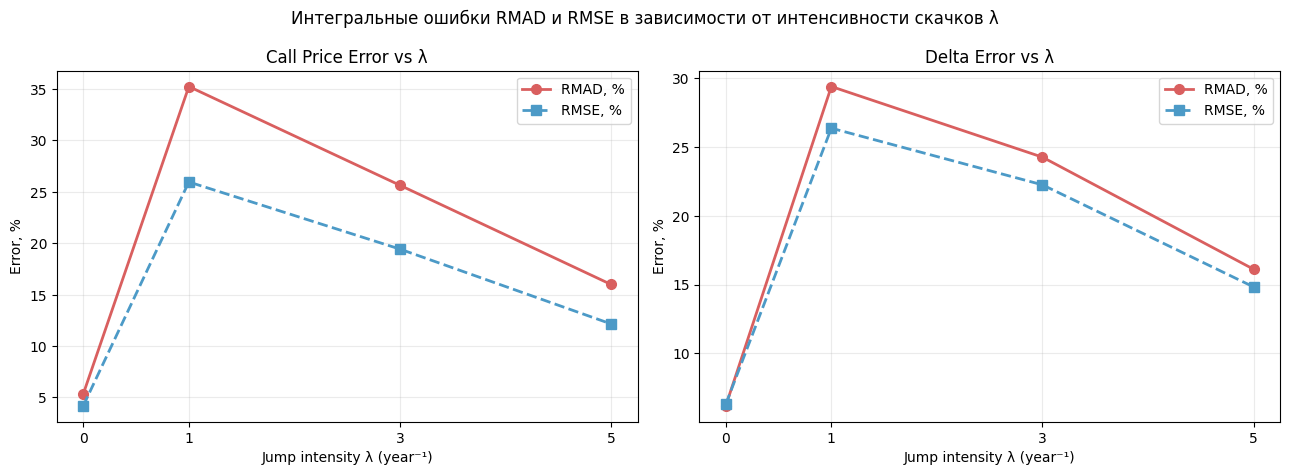

In [18]:
def read_csv_rows(path: Path) -> list[dict]:
    with path.open(encoding="utf-8-sig", newline="") as f:
        return list(csv.DictReader(f))

integral_data = {lmbd: read_csv_rows(studies[lmbd]["dir"] / "article_comparison.csv") for lmbd in LAMBDAS}
summary_data = {lmbd: read_csv_rows(studies[lmbd]["dir"] / "metrics_summary.csv") for lmbd in LAMBDAS}

table_rows = []
metrics_order = [("Цена", "RMAD, %"), ("Цена", "RMSE, %"), ("Цена", "NMAD, %"), ("Цена", "MSE"),
                 ("Delta", "RMAD, %"), ("Delta", "RMSE, %"), ("Delta", "NMAD, %"), ("Delta", "MSE")]
for qty, m_label in metrics_order:
    row_ref = next(r for r in integral_data[LAMBDAS[0]] if r["quantity"] == qty and r["metric"] == m_label)
    digits = int(row_ref["digits"])
    art = f"{float(row_ref['article']):.{digits}f}"
    vals = []
    for lmbd in LAMBDAS:
        r = next(x for x in integral_data[lmbd] if x["quantity"] == qty and x["metric"] == m_label)
        vals.append(f"<td style='text-align:right'><b>{float(r['current']):.{digits}f}</b> ({float(r['difference']):+.{digits}f})</td>")
    table_rows.append(f"<tr><td>{qty}</td><td>{m_label}</td><td style='text-align:right'>{art}</td>" + "".join(vals) + "</tr>")

headers_html = "".join(f"<th>λ = {lmbd:g} (расх.)</th>" for lmbd in LAMBDAS)
display(HTML(
    "<h4>Интегральные метрики по 30 моделям (среднее по 3 σ, 7 τ, 10 seed)</h4>"
    "<table><thead><tr><th>Величина</th><th>Метрика</th><th>Статья (BSM)</th>"
    + headers_html + "</tr></thead><tbody>" + "".join(table_rows) + "</tbody></table>"
))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (qty, title) in zip(axes, (("Цена", "Call Price Error vs λ"), ("Delta", "Delta Error vs λ"))):
    for metric_name, style, color in (("RMAD, %", "-o", "#D95F5F"), ("RMSE, %", "--s", "#4C9AC7")):
        y = [float(next(r["current"] for r in integral_data[l] if r["quantity"] == qty and r["metric"] == metric_name))
             for l in LAMBDAS]
        ax.plot(LAMBDAS, y, style, color=color, linewidth=2, markersize=7, label=metric_name)
    ax.set(title=title, xlabel="Jump intensity λ (year⁻¹)", ylabel="Error, %", xticks=LAMBDAS)
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle("Интегральные ошибки RMAD и RMSE в зависимости от интенсивности скачков λ")
fig.tight_layout()
plt.show()


### 12.2 Распределение ошибки по Moneyness ($m = S/K$)

Разбиение сечения $S/K \in [0.5, 2.0]$ ($K=100, \tau=0.36, \sigma=0.15$, среднее по 10 seed из `comparison_predictions.csv`) на три страты:
- **Deep OTM** ($S/K < 0.90$),
- **Near ATM** ($0.90 \le S/K \le 1.10$),
- **Deep ITM** ($S/K > 1.10$).


Страта Moneyness,Показатель,λ = 0,λ = 1,λ = 3,λ = 5
Deep OTM (S/K < 0.90),Цена: MAE (RMAD%),0.1245 (320.40%),0.6969 (2304.50%),0.3806 (1229.22%),0.2628 (824.07%)
,Delta: MAE,0.0050,0.0697,0.0470,0.0265
Near ATM (0.90 ≤ S/K ≤ 1.10),Цена: MAE (RMAD%),0.6547 (15.16%),4.5090 (106.46%),3.4512 (80.58%),2.0559 (47.87%)
,Delta: MAE,0.0375,0.1400,0.1276,0.0752
Deep ITM (S/K > 1.10),Цена: MAE (RMAD%),0.1034 (0.19%),0.6450 (1.17%),0.4395 (0.79%),0.2673 (0.48%)
,Delta: MAE,0.0119,0.0507,0.0384,0.0246


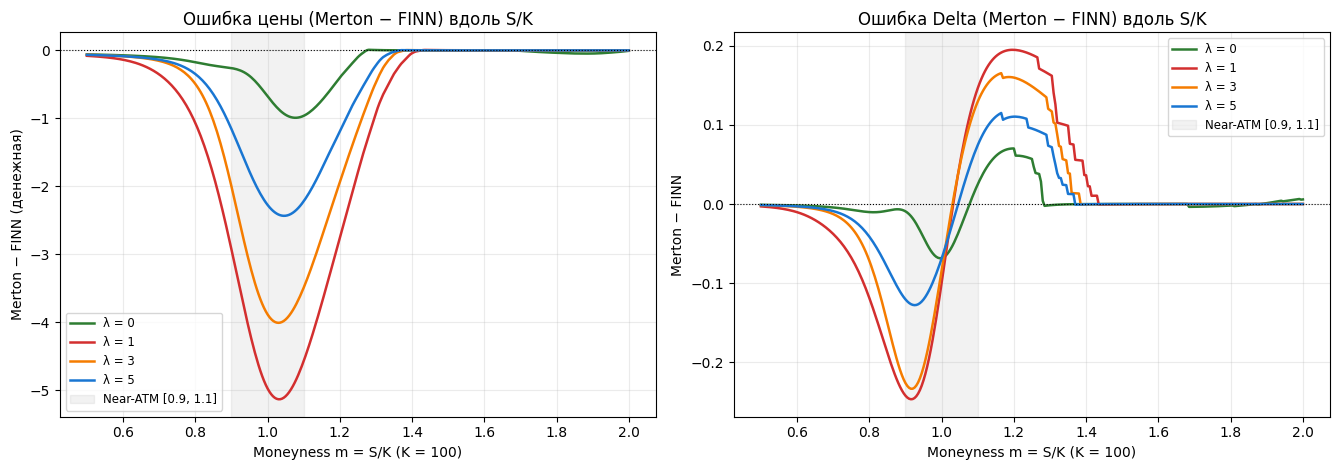

In [19]:
strata_defs = [
    ("Deep OTM (S/K < 0.90)", lambda m: m < 0.90),
    ("Near ATM (0.90 ≤ S/K ≤ 1.10)", lambda m: (m >= 0.90) & (m <= 1.10)),
    ("Deep ITM (S/K > 1.10)", lambda m: m > 1.10),
]

cross_section = {}
for lmbd in LAMBDAS:
    rows = read_csv_rows(studies[lmbd]["dir"] / "sigma_0.150/mean_10_seeds/comparison_predictions.csv")
    s = np.array([float(r["S"]) for r in rows])
    k = np.array([float(r["K"]) for r in rows])
    p_finn = np.array([float(r["price_finn_mean"]) for r in rows])
    p_ref = np.array([float(r.get("price_merton", r.get("price_bsm"))) for r in rows])
    d_finn = np.array([float(r["delta_finn_mean"]) for r in rows])
    d_ref = np.array([float(r.get("delta_merton", r.get("delta_bsm"))) for r in rows])
    cross_section[lmbd] = {"m": s / k, "s": s, "k": k,
                           "p_finn": p_finn, "p_ref": p_ref,
                           "d_finn": d_finn, "d_ref": d_ref}

strata_html = []
for s_name, cond in strata_defs:
    cells_p, cells_d = [], []
    for lmbd in LAMBDAS:
        cs = cross_section[lmbd]
        mask = cond(cs["m"])
        p_mae = np.mean(np.abs(cs["p_ref"][mask] - cs["p_finn"][mask]))
        p_rmad = 100.0 * np.sum(np.abs(cs["p_ref"][mask] - cs["p_finn"][mask])) / (np.sum(np.abs(cs["p_ref"][mask])) + 1e-12)
        d_mae = np.mean(np.abs(cs["d_ref"][mask] - cs["d_finn"][mask]))
        cells_p.append(f"<td style='text-align:right'>{p_mae:.4f} ({p_rmad:.2f}%)</td>")
        cells_d.append(f"<td style='text-align:right'>{d_mae:.4f}</td>")
    strata_html.append(f"<tr><td><b>{s_name}</b></td><td>Цена: MAE (RMAD%)</td>" + "".join(cells_p) + "</tr>")
    strata_html.append(f"<tr><td></td><td>Delta: MAE</td>" + "".join(cells_d) + "</tr>")

display(HTML(
    "<h4>Ошибки по стратам Moneyness S/K (σ = 0.15, τ = 0.36, среднее 10 seed)</h4>"
    "<table><thead><tr><th>Страта Moneyness</th><th>Показатель</th>"
    + "".join(f"<th>λ = {l:g}</th>" for l in LAMBDAS)
    + "</tr></thead><tbody>" + "".join(strata_html) + "</tbody></table>"
))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
for lmbd in LAMBDAS:
    cs = cross_section[lmbd]
    axes[0].plot(cs["m"], cs["p_ref"] - cs["p_finn"], color=COLORS[lmbd], linewidth=1.8, label=f"λ = {lmbd:g}")
    axes[1].plot(cs["m"], cs["d_ref"] - cs["d_finn"], color=COLORS[lmbd], linewidth=1.8, label=f"λ = {lmbd:g}")
for ax, title, ylabel in zip(axes, ("Ошибка цены (Merton − FINN) вдоль S/K", "Ошибка Delta (Merton − FINN) вдоль S/K"),
                             ("Merton − FINN (денежная)", "Merton − FINN")):
    ax.axvspan(0.9, 1.1, color="gray", alpha=0.10, label="Near-ATM [0.9, 1.1]")
    ax.axhline(0, color="black", linewidth=0.8, linestyle=":")
    ax.set(title=title, xlabel="Moneyness m = S/K (K = 100)", ylabel=ylabel)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8.5)
fig.tight_layout()
plt.show()


### 12.3 Чувствительность к сроку до экспирации ($\tau \in [0.24, 0.48]$)

Зависимость ошибки цены и Delta (RMAD и MSE) от срока до погашения $\tau$ по готовым таблицам `metrics_summary.csv` при $\sigma = 0.15$.


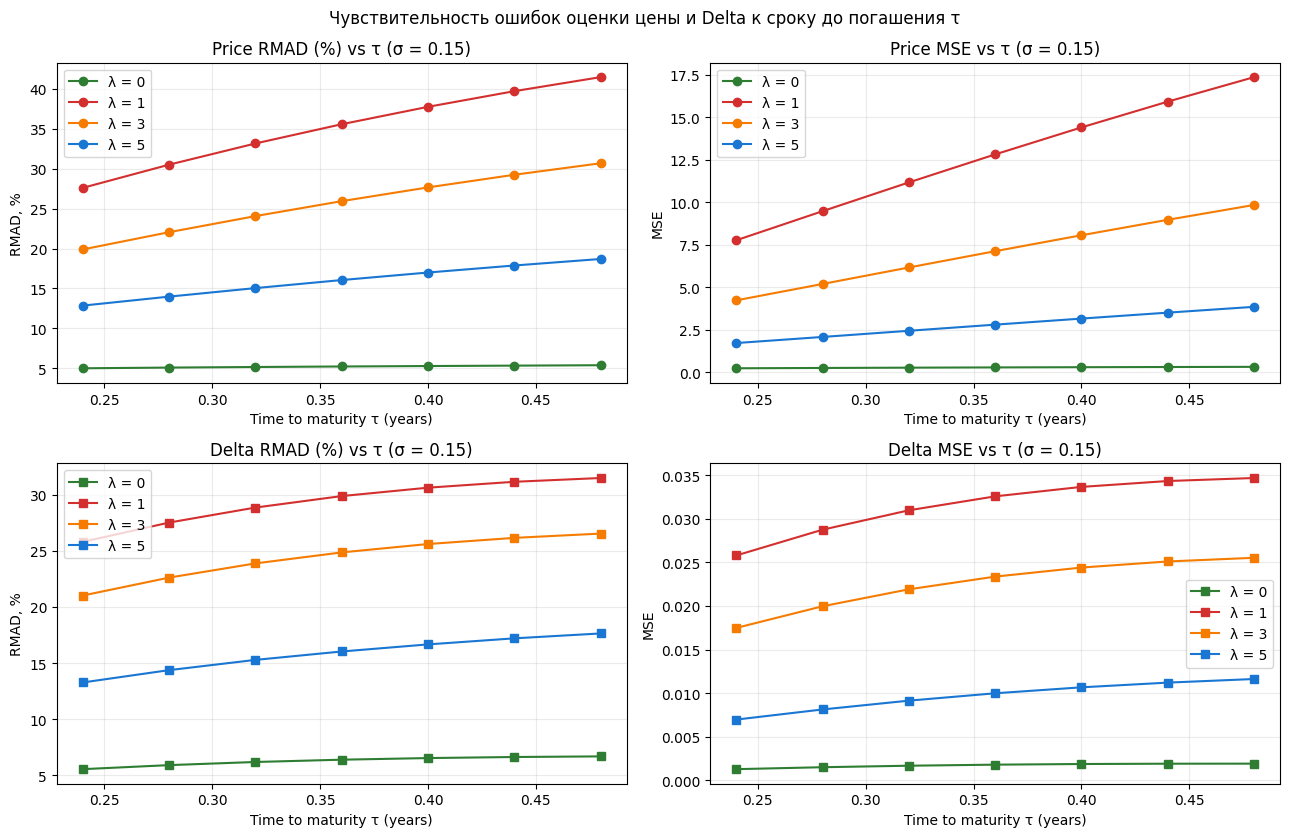

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for lmbd in LAMBDAS:
    rows_p = sorted((r for r in summary_data[lmbd] if float(r["sigma"]) == 0.15 and r["quantity"] == "price"),
                    key=lambda r: float(r["tau"]))
    rows_d = sorted((r for r in summary_data[lmbd] if float(r["sigma"]) == 0.15 and r["quantity"] == "delta"),
                    key=lambda r: float(r["tau"]))
    taus = [float(r["tau"]) for r in rows_p]
    axes[0, 0].plot(taus, [100 * float(r["RMAD_mean"]) for r in rows_p], "-o", color=COLORS[lmbd], label=f"λ = {lmbd:g}")
    axes[0, 1].plot(taus, [float(r["MSE_mean"]) for r in rows_p], "-o", color=COLORS[lmbd], label=f"λ = {lmbd:g}")
    axes[1, 0].plot(taus, [100 * float(r["RMAD_mean"]) for r in rows_d], "-s", color=COLORS[lmbd], label=f"λ = {lmbd:g}")
    axes[1, 1].plot(taus, [float(r["MSE_mean"]) for r in rows_d], "-s", color=COLORS[lmbd], label=f"λ = {lmbd:g}")

titles = [
    ("Price RMAD (%) vs τ (σ = 0.15)", "RMAD, %"),
    ("Price MSE vs τ (σ = 0.15)", "MSE"),
    ("Delta RMAD (%) vs τ (σ = 0.15)", "RMAD, %"),
    ("Delta MSE vs τ (σ = 0.15)", "MSE"),
]
for ax, (title, ylabel) in zip(axes.flat, titles):
    ax.set(title=title, xlabel="Time to maturity τ (years)", ylabel=ylabel)
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle("Чувствительность ошибок оценки цены и Delta к сроку до погашения τ")
fig.tight_layout()
plt.show()


### 12.4 Асимптота функции потерь (Unhedgeable Risk)

Сравнение кривых сходимости `val_loss` из `history_mean.csv` и лучших значений `best_validation_loss` по всем 30 моделям каждой серии (`training_summary.json`).


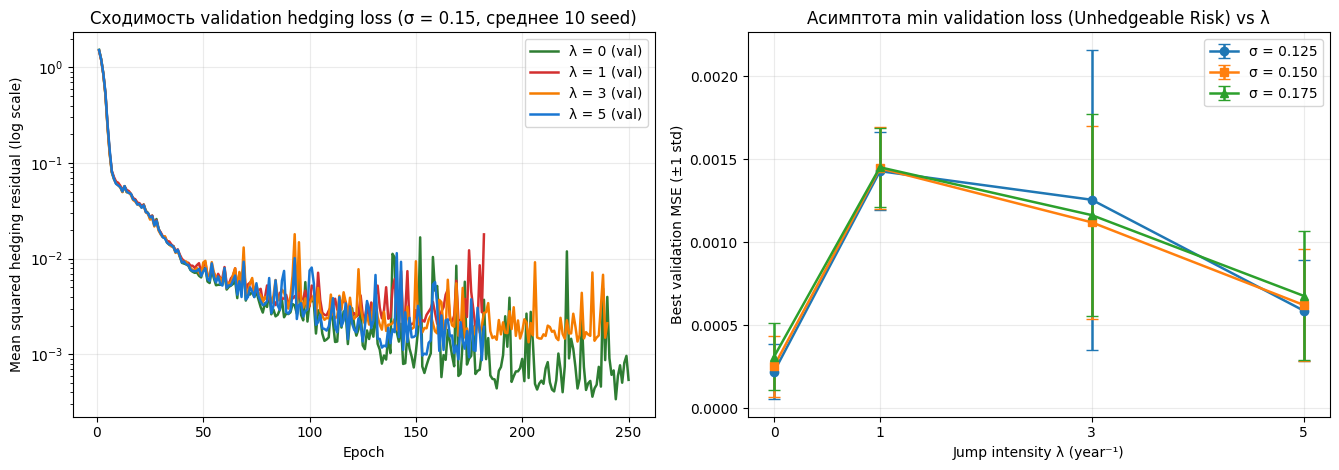

Интенсивность λ,σ = 0.125,σ = 0.150,σ = 0.175
λ = 0,0.00022 ± 0.00017,0.00025 ± 0.00018,0.00031 ± 0.00020
λ = 1,0.00143 ± 0.00023,0.00144 ± 0.00025,0.00145 ± 0.00024
λ = 3,0.00125 ± 0.00090,0.00112 ± 0.00058,0.00116 ± 0.00061
λ = 5,0.00059 ± 0.00030,0.00062 ± 0.00034,0.00068 ± 0.00039


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

loss_summary_rows = []
for lmbd in LAMBDAS:
    hist = read_csv_rows(studies[lmbd]["dir"] / "sigma_0.150/mean_10_seeds/history_mean.csv")
    epochs = [int(float(r["epoch"])) for r in hist]
    val_mean = [float(r["val_loss_mean"]) for r in hist]
    axes[0].semilogy(epochs, val_mean, color=COLORS[lmbd], linewidth=1.8, label=f"λ = {lmbd:g} (val)")

    per_sigma_means = {}
    for sigma in (0.125, 0.150, 0.175):
        vals = []
        for s_file in sorted((studies[lmbd]["dir"] / f"sigma_{sigma:.3f}").glob("seed_*/training_summary.json")):
            vals.append(json.loads(s_file.read_text(encoding="utf-8"))["best_validation_loss"])
        per_sigma_means[sigma] = (float(np.mean(vals)), float(np.std(vals, ddof=1)))
    loss_summary_rows.append((lmbd, per_sigma_means))

axes[0].set(title="Сходимость validation hedging loss (σ = 0.15, среднее 10 seed)",
            xlabel="Epoch", ylabel="Mean squared hedging residual (log scale)")
axes[0].grid(alpha=0.25)
axes[0].legend()

for sigma, marker in ((0.125, "-o"), (0.150, "-s"), (0.175, "-^")):
    y = [row[1][sigma][0] for row in loss_summary_rows]
    yerr = [row[1][sigma][1] for row in loss_summary_rows]
    axes[1].errorbar(LAMBDAS, y, yerr=yerr, fmt=marker, capsize=4, linewidth=1.8, label=f"σ = {sigma:.3f}")

axes[1].set(title="Асимптота min validation loss (Unhedgeable Risk) vs λ",
            xlabel="Jump intensity λ (year⁻¹)", ylabel="Best validation MSE (±1 std)", xticks=LAMBDAS)
axes[1].grid(alpha=0.25)
axes[1].legend()
fig.tight_layout()
plt.show()

html_loss = []
for lmbd, per_sigma in loss_summary_rows:
    cells_str = "".join(f"<td style='text-align:right'>{per_sigma[s][0]:.5f} ± {per_sigma[s][1]:.5f}</td>" for s in (0.125, 0.150, 0.175))
    html_loss.append(f"<tr><td><b>λ = {lmbd:g}</b></td>{cells_str}</tr>")
display(HTML(
    "<h4>Лучший validation hedging loss при сходимости (среднее ± std по 10 seed)</h4>"
    "<table><thead><tr><th>Интенсивность λ</th><th>σ = 0.125</th><th>σ = 0.150</th><th>σ = 0.175</th></tr></thead>"
    "<tbody>" + "".join(html_loss) + "</tbody></table>"
))


### 12.5 Кривая подразумеваемой волатильности (Implied Volatility Smile)

Перевод готовых цен `price_merton` и `price_finn_mean` из `comparison_predictions.csv` ($\sigma = 0.15, \tau = 0.36, K = 100$) в подразумеваемую волатильность Блэка–Шоулза $\sigma_{\text{IV}}(S/K)$.


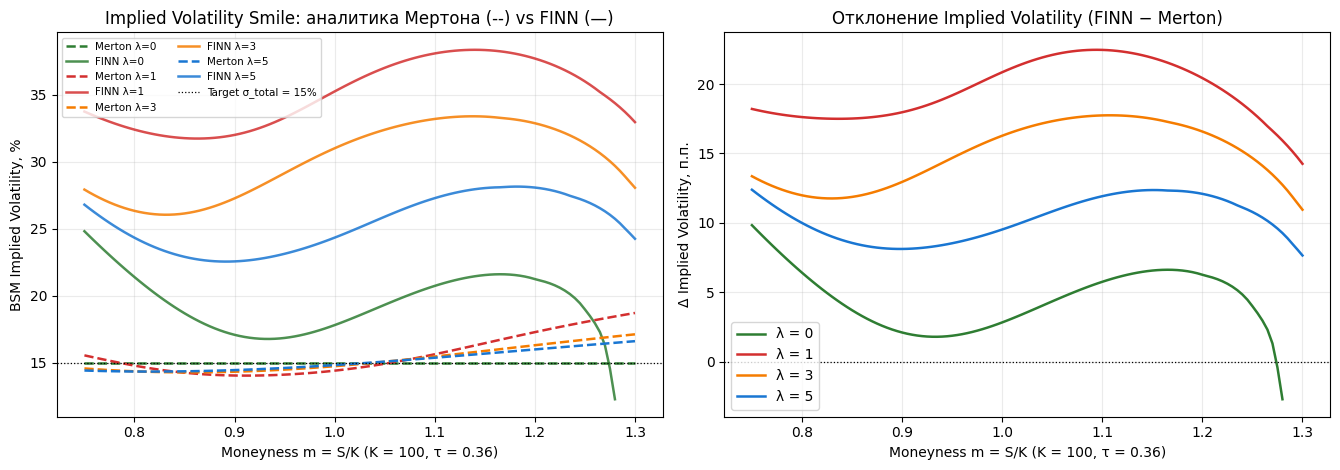

In [22]:
def bs_call_scalar(s: float, k: float, tau: float, vol: float) -> float:
    if vol <= 0 or tau <= 0:
        return max(s - k, 0.0)
    srt = vol * math.sqrt(tau)
    d1 = (math.log(s / k) + 0.5 * srt * srt) / srt
    d2 = d1 - srt
    return float(s * ndtr(d1) - k * ndtr(d2))

def implied_vol_vec(prices: np.ndarray, spots: np.ndarray, strikes: np.ndarray, tau: float) -> np.ndarray:
    out = np.full_like(prices, np.nan, dtype=float)
    for idx, (p, s, k) in enumerate(zip(prices, spots, strikes)):
        intrinsic = max(float(s - k), 0.0)
        if p <= intrinsic + 1e-5 or p >= s - 1e-5:
            continue
        try:
            out[idx] = brentq(lambda v: bs_call_scalar(float(s), float(k), tau, v) - float(p),
                              1e-4, 2.0, xtol=1e-8)
        except ValueError:
            continue
    return out

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
for lmbd in LAMBDAS:
    cs = cross_section[lmbd]
    window = (cs["m"] >= 0.75) & (cs["m"] <= 1.30)
    m_w = cs["m"][window]
    iv_ref = implied_vol_vec(cs["p_ref"][window], cs["s"][window], cs["k"][window], 0.36)
    iv_finn = implied_vol_vec(cs["p_finn"][window], cs["s"][window], cs["k"][window], 0.36)
    axes[0].plot(m_w, 100 * iv_ref, "--", color=COLORS[lmbd], linewidth=1.8, label=f"Merton λ={lmbd:g}")
    axes[0].plot(m_w, 100 * iv_finn, "-", color=COLORS[lmbd], linewidth=1.8, alpha=0.85, label=f"FINN λ={lmbd:g}")
    axes[1].plot(m_w, 100 * (iv_finn - iv_ref), "-", color=COLORS[lmbd], linewidth=1.8, label=f"λ = {lmbd:g}")

axes[0].axhline(15.0, color="black", linestyle=":", linewidth=0.9, label="Target σ_total = 15%")
axes[0].set(title="Implied Volatility Smile: аналитика Мертона (--) vs FINN (—)",
            xlabel="Moneyness m = S/K (K = 100, τ = 0.36)", ylabel="BSM Implied Volatility, %")
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=7.5, ncol=2)

axes[1].axhline(0.0, color="black", linestyle=":", linewidth=0.9)
axes[1].set(title="Отклонение Implied Volatility (FINN − Merton)",
            xlabel="Moneyness m = S/K (K = 100, τ = 0.36)", ylabel="Δ Implied Volatility, п.п.")
axes[1].grid(alpha=0.25)
axes[1].legend()
fig.tight_layout()
plt.show()


### 12.6 Гладкость Дельты ($\Delta$) в районе страйка

Сопоставление сетевой $\Delta_{\text{FINN}}$ (по готовой мелкой сетке `comparison_predictions.csv` с шагом $\Delta S = 0.5$) с аналитической $\Delta_{\text{Merton}}$.


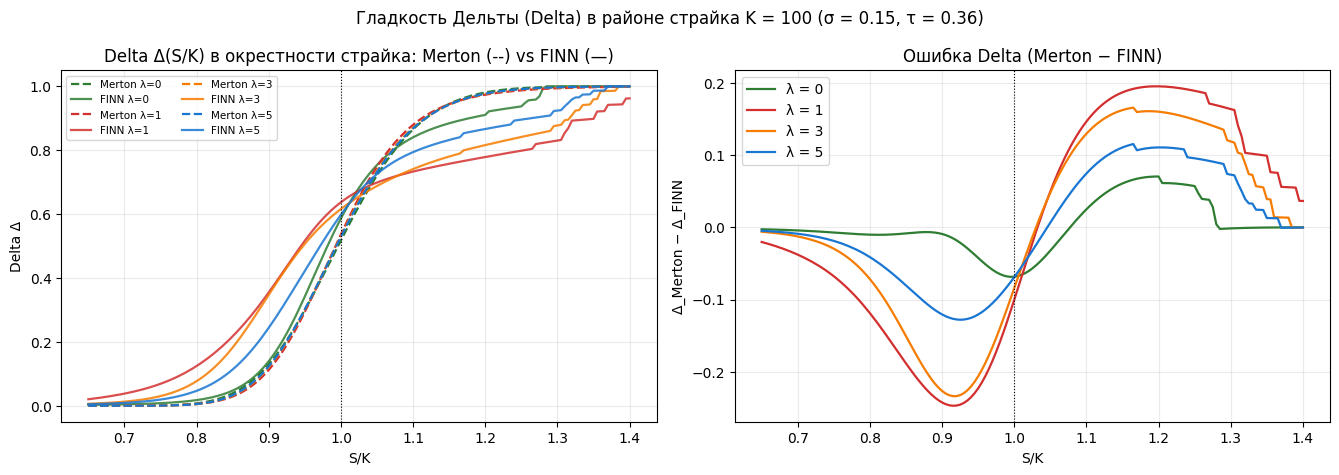

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
for lmbd in LAMBDAS:
    cs = cross_section[lmbd]
    m = cs["m"]
    zoom = (m >= 0.65) & (m <= 1.40)
    axes[0].plot(m[zoom], cs["d_ref"][zoom], "--", color=COLORS[lmbd], linewidth=1.6, label=f"Merton λ={lmbd:g}")
    axes[0].plot(m[zoom], cs["d_finn"][zoom], "-", color=COLORS[lmbd], linewidth=1.6, alpha=0.85, label=f"FINN λ={lmbd:g}")
    axes[1].plot(m[zoom], cs["d_ref"][zoom] - cs["d_finn"][zoom], "-", color=COLORS[lmbd], linewidth=1.6, label=f"λ = {lmbd:g}")

axes[0].set(title="Delta Δ(S/K) в окрестности страйка: Merton (--) vs FINN (—)", xlabel="S/K", ylabel="Delta Δ")
axes[1].set(title="Ошибка Delta (Merton − FINN)", xlabel="S/K", ylabel="Δ_Merton − Δ_FINN")

for ax in axes.flat:
    ax.axvline(1.0, color="black", linestyle=":", linewidth=0.8)
    ax.grid(alpha=0.25)
axes[0].legend(fontsize=7.5, ncol=2)
axes[1].legend()
fig.suptitle("Гладкость Дельты (Delta) в районе страйка K = 100 (σ = 0.15, τ = 0.36)")
fig.tight_layout()
plt.show()
